In [2]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle").strip()

In [3]:
!kaggle competitions download -c predicting-assessment-scores-hw1-ucu-ai-2026

100% 26.2M/26.2M [00:00<00:00, 110MB/s]



In [4]:
!unzip ./predicting-assessment-scores-hw1-ucu-ai-2026.zip -d ./data

Archive:  ./predicting-assessment-scores-hw1-ucu-ai-2026.zip
  inflating: ./data/README.md        
  inflating: ./data/data_dictionary.csv  
  inflating: ./data/sample_submission.csv  
  inflating: ./data/test.csv         
  inflating: ./data/train.csv        
  inflating: ./data/unlabeled.csv    


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [6]:
train_path = "data/train.csv"
test_path = "data/test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
display(train_df.head())


Train shape: (441000, 17)
Test shape: (189000, 16)


,record_id,learner_age,gender_group,program_track,study_time,attendance_rate,home_internet,sleep_duration,rest_quality,learning_routine,campus_resources,assessment_level,study_minutes,engagement_index,intake_marker,registration_group,assessment_score
0,1572288,18.0,other,b.com,0.78,97.8,no,5.15,poor,mixed,low,moderate,43.9,70.74,0.743351,G06,48.5
1,1065516,21.0,other,b.tech,1.65,77.3,yes,6.41,poor,mixed,high,moderate,99.0,55.89,0.971166,G08,50.0
2,1480349,20.0,other,diploma,3.29,61.2,no,8.77,poor,self-study,low,easy,200.5,53.53,0.764103,G11,53.0
3,1128337,24.0,male,diploma,5.33,66.9,no,6.42,good,coaching,medium,moderate,332.0,67.67,0.865821,G10,89.9
4,1794604,23.0,female,bca,6.68,69.3,no,5.63,average,self-study,medium,easy,410.7,75.14,0.223452,G02,91.8


# **EDA**

In [6]:
print(train_df.describe())

          record_id    learner_age     study_time  attendance_rate  \
count  4.410000e+05  427793.000000  426806.000000    427780.000000   
mean   1.450699e+06      20.546870       4.040254        72.101106   
std    2.597648e+05       2.259262       2.505806        17.584797   
min    1.000000e+06      17.000000       0.000000        38.700000   
25%    1.225944e+06      19.000000       1.960000        57.000000   
50%    1.451013e+06      21.000000       4.010000        72.600000   
75%    1.675431e+06      23.000000       6.070000        87.400000   
max    1.899994e+06      24.000000      32.240000       150.000000   

       sleep_duration  study_minutes  engagement_index  intake_marker  \
count   427822.000000  427845.000000     427648.000000  427935.000000   
mean         7.071411     240.301743         64.317714       0.499874   
std          1.746177     142.061317         16.277773       0.288912   
min          3.850000       0.000000         16.410000       0.000005   
25% 

In [ ]:
print("Raw dtypes:\n", train_df.dtypes)
print("\nNull counts:\n", train_df.isna().sum())

Raw dtypes:
 record_id               int64
learner_age           float64
gender_group           object
program_track          object
study_time            float64
attendance_rate       float64
home_internet          object
sleep_duration        float64
rest_quality           object
learning_routine       object
campus_resources       object
assessment_level       object
study_minutes         float64
engagement_index      float64
intake_marker         float64
registration_group     object
assessment_score      float64
dtype: object

Null counts:
 record_id                 0
learner_age           13207
gender_group           8871
program_track          8968
study_time            14194
attendance_rate       13220
home_internet          8820
sleep_duration        13178
rest_quality           8740
learning_routine       8895
campus_resources       8930
assessment_level       8869
study_minutes         13155
engagement_index      13352
intake_marker         13065
registration_group     8782


In [ ]:
train_df.dropna().shape

(302244, 17)

Початково датасет містить 441 000 рядків. Якщо видалити всі рядки з хоча б одним пропуском, залишиться лише 302 244, тобто втратимо майже третину даних. Причина в тому, що пропуски розкидані по багатьох колонках, тож кожна окрема колонка «забирає» небагато, але разом вони зачіпають багато різних рядків. Видаляти такі рядки недоцільно, бо ми втратимо багато корисної інформації в заповнених колонках. Тому пропуски краще імпутувати.

In [8]:
train_df.dropna()['assessment_score'].mean()

np.float64(62.529770364341395)

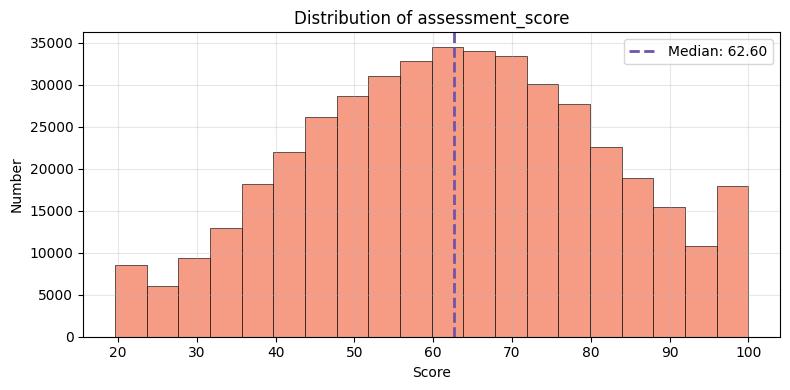

In [ ]:
score = train_df["assessment_score"].dropna()
median_score = score.median()

plt.figure(figsize=(8, 4))
plt.hist(score, bins=20, color="#F58B70", edgecolor="black", linewidth=0.5, alpha=0.85)
plt.axvline(median_score, color="#6F55A8", linestyle="--", linewidth=2,
            label=f"Median: {median_score:.2f}")
plt.xlabel("Score")
plt.ylabel("Number")
plt.title("Distribution of assessment_score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

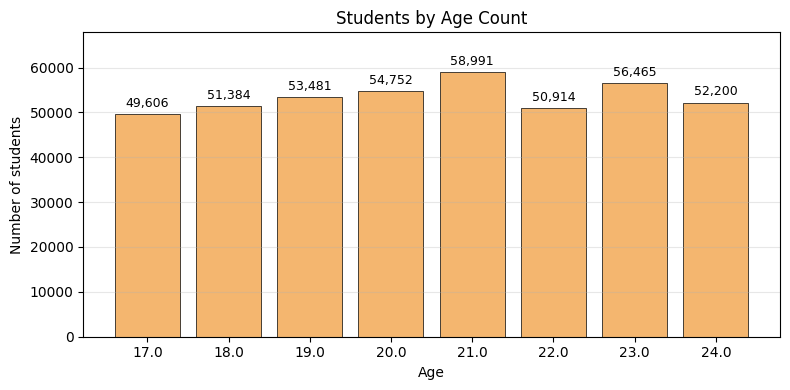

In [ ]:
age_counts = train_df["learner_age"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
bars = plt.bar(age_counts.index.astype(str), age_counts.values,
               color="#F4B66F", edgecolor="black", linewidth=0.5)
plt.bar_label(bars, labels=[f"{count:,}" for count in age_counts.values], padding=3, fontsize=9)
plt.ylim(0, age_counts.max() * 1.15)
plt.xlabel("Age")
plt.ylabel("Number of students")
plt.title("Students by Age Count")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

learner_age: значення в діапазоні 17-24 без аномалій, ~3% пропусків

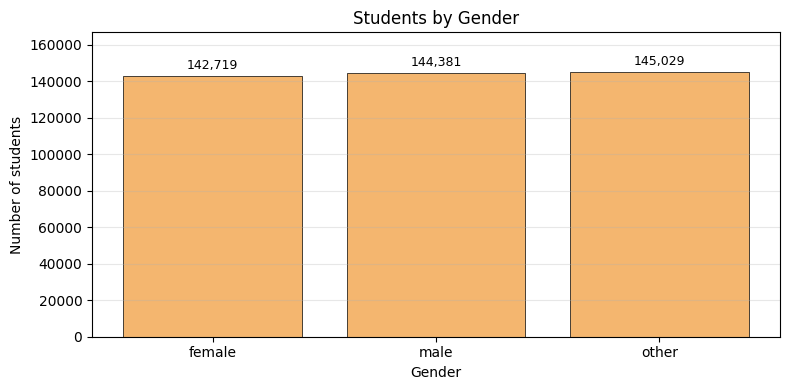

In [ ]:
gender_counts = train_df["gender_group"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
bars = plt.bar(gender_counts.index.astype(str), gender_counts.values,
               color="#F4B66F", edgecolor="black", linewidth=0.5)
plt.bar_label(bars, labels=[f"{count:,}" for count in gender_counts.values], padding=3, fontsize=9)
plt.ylim(0, gender_counts.max() * 1.15)
plt.xlabel("Gender")
plt.ylabel("Number of students")
plt.title("Students by Gender")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
train_df.groupby('gender_group')['assessment_score'].mean()

,assessment_score
gender_group,
female,62.542938
male,62.236294
other,62.746800


gender_group: категорії збалансовані, є ~2% пропусків, середній score майже однаковий для всіх груп, тож ознака малоінформативна.

In [ ]:
program_counts = train_df["program_track"].value_counts().sort_index()
print(program_counts)

program_track
 B.COM        1133
 B.SC         1150
 B.TECH       1421
 BA            665
 BBA           761
 BCA           856
 DIPLOMA       496
b.com        74610
b.sc         75564
b.tech       88629
ba           41896
bba          51122
bca          59942
diploma      33787
Name: count, dtype: int64


In [9]:
train_df["program_track"] = train_df["program_track"].str.strip().str.lower()
print(train_df["program_track"].value_counts())

program_track
b.tech     90050
b.sc       76714
b.com      75743
bca        60798
bba        51883
ba         42561
diploma    34283
Name: count, dtype: int64


In [10]:
train_df.groupby('program_track')['assessment_score'].mean()

,assessment_score
program_track,
b.com,62.473646
b.sc,62.319625
b.tech,62.566038
ba,61.919824
bba,63.221899
bca,62.560332
diploma,62.349482


program_track: були дублі через регістр і пробіли, після strip().lower() лишилось 7 чистих категорій, але на score вони майже не впливають.

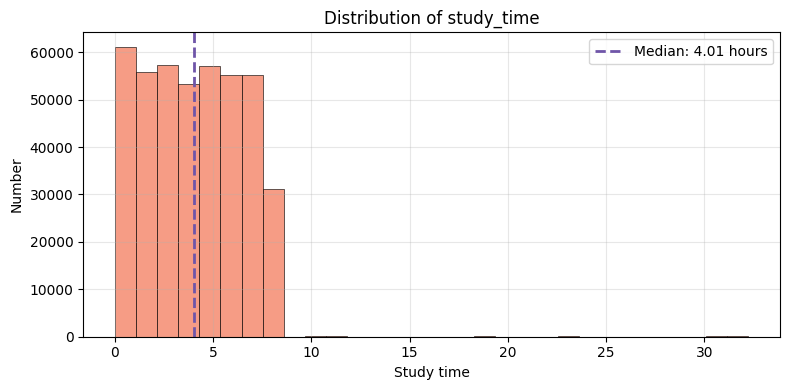

In [ ]:
study_time = train_df["study_time"].dropna()
median_study_time = study_time.median()

plt.figure(figsize=(8, 4))
plt.hist(study_time, bins=30, color="#F58B70", edgecolor="black", linewidth=0.5, alpha=0.85)
plt.axvline(median_study_time, color="#6F55A8", linestyle="--", linewidth=2,
            label=f"Median: {median_study_time:.2f} hours")
plt.xlabel("Study time")
plt.ylabel("Number")
plt.title("Distribution of study_time")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

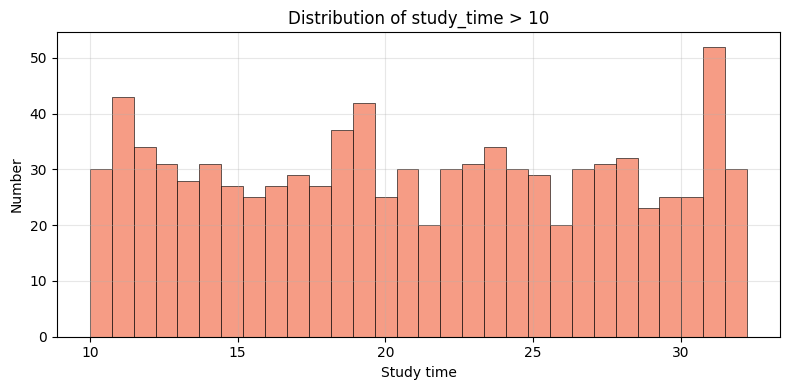

In [ ]:
study_time_tail = train_df[train_df["study_time"]>=10]["study_time"].dropna()

plt.figure(figsize=(8, 4))
plt.hist(study_time_tail, bins=30, color="#F58B70", edgecolor="black", linewidth=0.5, alpha=0.85)
plt.xlabel("Study time")
plt.ylabel("Number")
plt.title("Distribution of study_time > 10")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
outliers = train_df[train_df['study_time'] >= 10]
outliers[['study_time', 'study_minutes']].head(20)

,study_time,study_minutes
102,18.72,296.3
410,17.36,247.0
678,17.84,277.1
1633,22.12,319.0
1828,18.00,268.9
2104,31.12,463.3
2390,16.28,244.1
2450,23.16,363.8
3534,21.12,328.7
4981,24.32,361.7


study_time: є нереалістичні значення до 32 годин на добу, можна спробувати відновити такі викиди з колонки study_minutes, де ці значення знаїодяться в межах норми.

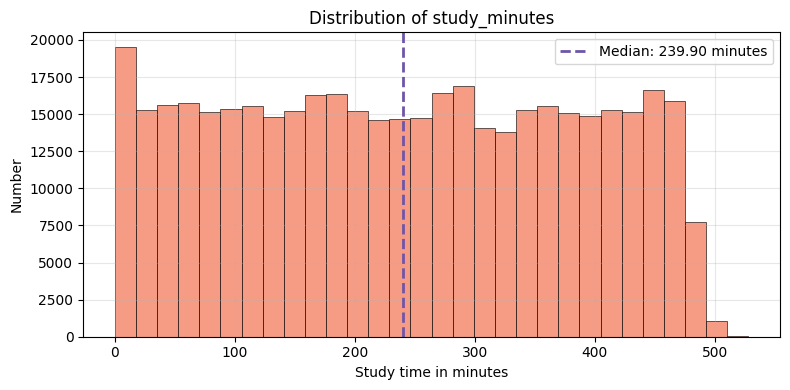

In [ ]:
study_minutes = train_df["study_minutes"].dropna()
median_study_minutes = study_minutes.median()

plt.figure(figsize=(8, 4))
plt.hist(study_minutes, bins=30, color="#F58B70", edgecolor="black", linewidth=0.5, alpha=0.85)
plt.axvline(median_study_minutes, color="#6F55A8", linestyle="--", linewidth=2,
            label=f"Median: {median_study_minutes:.2f} minutes")
plt.xlabel("Study time in minutes")
plt.ylabel("Number")
plt.title("Distribution of study_minutes")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

study_minutes: значення виглядають стабільніше за study_time, немає есктремальних значень (>10 год)

In [ ]:
train_df['study_time_expected'] = train_df['study_minutes'] / 60
train_df['study_time_diff'] = train_df['study_time'] - train_df['study_time_expected']

train_df['study_time_diff'].describe()


,study_time_diff
count,414105.000000
mean,0.035375
std,0.793417
min,-0.975000
25%,-0.133333
50%,0.000000
75%,0.131667
max,24.208333


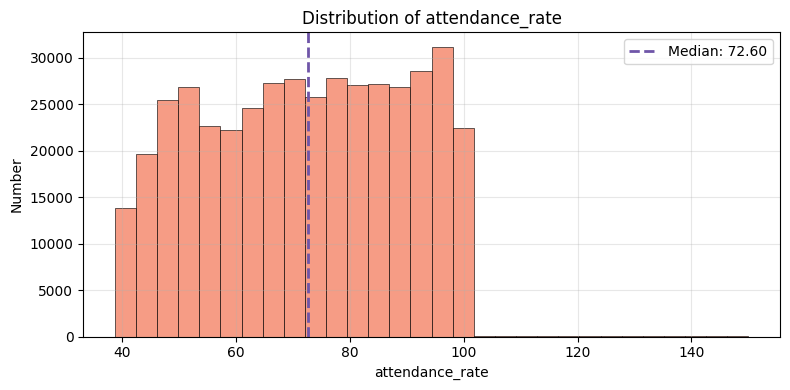

In [ ]:
attendance_rate = train_df["attendance_rate"].dropna()
median_attendance_rate = attendance_rate.median()

plt.figure(figsize=(8, 4))
plt.hist(attendance_rate, bins=30, color="#F58B70", edgecolor="black", linewidth=0.5, alpha=0.85)
plt.axvline(median_attendance_rate, color="#6F55A8", linestyle="--", linewidth=2,
            label=f"Median: {median_attendance_rate:.2f}")
plt.xlabel("attendance_rate")
plt.ylabel("Number")
plt.title("Distribution of attendance_rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print(train_df[train_df["attendance_rate"]>100]["attendance_rate"].describe())

count    747.000000
mean     126.709438
std       15.299274
min      100.050000
25%      113.175000
50%      127.800000
75%      140.325000
max      150.000000
Name: attendance_rate, dtype: float64


attendance_rate: 747 значень > 100% (до 150%) неможливі за змістом.

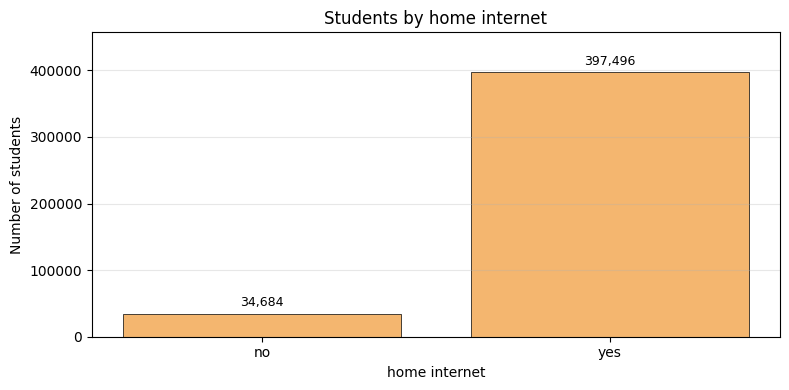

In [ ]:
home_internet_counts = train_df["home_internet"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
bars = plt.bar(home_internet_counts.index.astype(str), home_internet_counts.values,
               color="#F4B66F", edgecolor="black", linewidth=0.5)
plt.bar_label(bars, labels=[f"{count:,}" for count in home_internet_counts.values], padding=3, fontsize=9)
plt.ylim(0, home_internet_counts.max() * 1.15)
plt.xlabel("home internet")
plt.ylabel("Number of students")
plt.title("Students by home internet")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
train_df.groupby('home_internet')['assessment_score'].mean()

,assessment_score
home_internet,
no,62.511887
yes,62.501304


home_internet: середній score для yes і no практично однаковий, тож може не дати сильного сигналу.

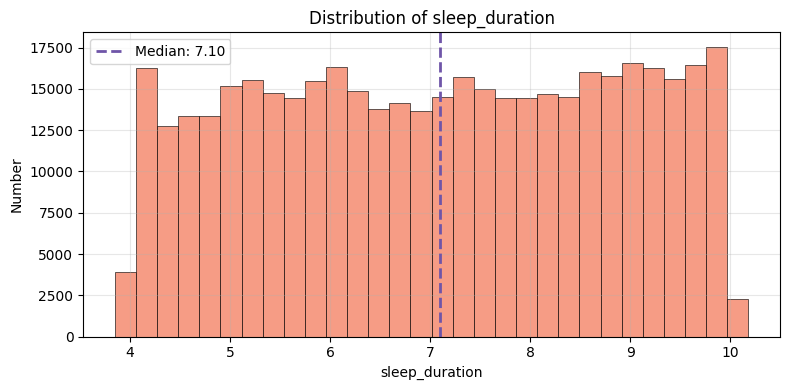

In [ ]:
sleep = train_df["sleep_duration"].dropna()
median_sleep = sleep.median()

plt.figure(figsize=(8, 4))
plt.hist(sleep, bins=30, color="#F58B70", edgecolor="black", linewidth=0.5, alpha=0.85)
plt.axvline(median_sleep, color="#6F55A8", linestyle="--", linewidth=2,
            label=f"Median: {median_sleep:.2f}")
plt.xlabel("sleep_duration")
plt.ylabel("Number")
plt.title("Distribution of sleep_duration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

sleep_duration: значення в розумному діапазоні (≈3.9-10.2 год), викидів немає

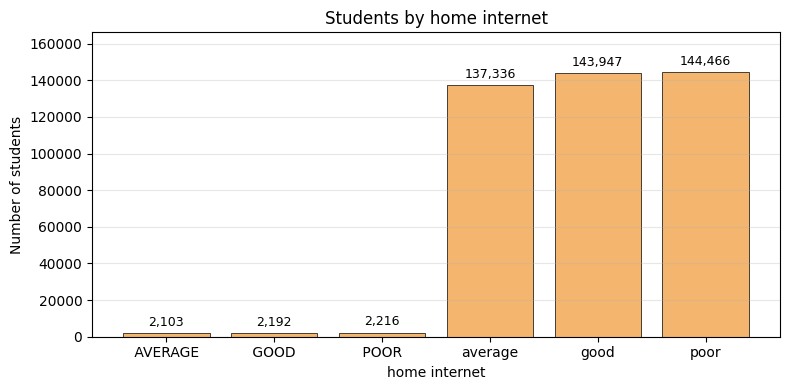

In [ ]:
rest_qality_counts = train_df["rest_quality"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
bars = plt.bar(rest_qality_counts.index.astype(str), rest_qality_counts.values,
               color="#F4B66F", edgecolor="black", linewidth=0.5)
plt.bar_label(bars, labels=[f"{count:,}" for count in rest_qality_counts.values], padding=3, fontsize=9)
plt.ylim(0, rest_qality_counts.max() * 1.15)
plt.xlabel("home internet")
plt.ylabel("Number of students")
plt.title("Students by home internet")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
train_df["rest_quality"] = train_df["rest_quality"].str.lower().str.strip()
train_df["rest_quality"].value_counts().sort_index()

,count
rest_quality,
average,139439
good,146139
poor,146682


In [14]:
train_df.groupby('rest_quality')['assessment_score'].mean()

,assessment_score
rest_quality,
average,62.615151
good,67.924721
poor,57.004230


rest_quality: були дублі через регістр/пробіли, після очищення 3 категорії (poor / average / good); середній score досить відрізняється від категорії

In [ ]:
train_df["learning_routine"].value_counts().sort_index()


,count
learning_routine,
COACHING,1339
GROUP STUDY,1300
MIXED,1267
ONLINE VIDEOS,1328
SELF-STUDY,1401
coaching,88934
group study,83066
mixed,83316
online videos,81591


In [15]:
train_df["learning_routine"] = train_df["learning_routine"].str.lower().str.strip()
train_df["learning_routine"].value_counts().sort_index()



,count
learning_routine,
coaching,90273
group study,84366
mixed,84583
online videos,82919
self-study,89964


In [16]:
train_df.groupby('learning_routine')['assessment_score'].mean()

,assessment_score
learning_routine,
coaching,69.255214
group study,60.573791
mixed,65.126950
online videos,59.738015
self-study,57.633467


learning_routine: були дублі через регістр, після очищення 5 категорій; ознака сильно впливає на score

In [ ]:
train_df["campus_resources"].value_counts().sort_index()


,count
campus_resources,
high,139503
low,145683
medium,146884


In [17]:
train_df.groupby('campus_resources')['assessment_score'].mean()

,assessment_score
campus_resources,
high,66.712624
low,57.972516
medium,63.008766


campus_resources: категорії чисті й збалансовані; ознака помітно впливає на score

In [ ]:
train_df["assessment_level"].value_counts().sort_index()


,count
assessment_level,
easy,121053
hard,68330
moderate,242748


In [18]:
train_df.groupby('assessment_level')['assessment_score'].mean()

,assessment_score
assessment_level,
easy,62.258295
hard,62.698720
moderate,62.587962


assessment_level: категорії чисті, але середній score майже однаковий для easy / moderate / hard, тож ознака, схоже, неінформативна.

In [ ]:
train_df["registration_group"].value_counts().sort_index()

,count
registration_group,
G01,35945
G02,35996
G03,35823
G04,35992
G05,36214
G06,35764
G07,36158
G08,36284
G09,35632


In [19]:
train_df.groupby('registration_group')['assessment_score'].mean()

,assessment_score
registration_group,
G01,62.485879
G02,62.452306
G03,62.652922
G04,62.447867
G05,62.600103
G06,62.581318
G07,62.371626
G08,62.582123
G09,62.366747


registration_group: 12 майже рівних груп (G01–G12) без видимого сенсу, виглядає як ідентифікатор без сигналу.

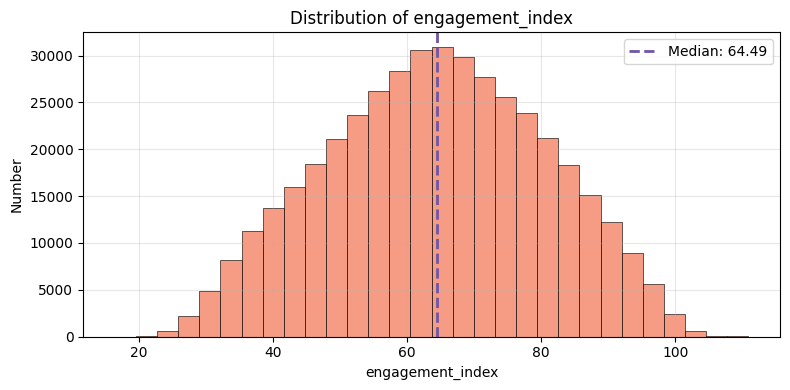

In [ ]:
engagement_index = train_df["engagement_index"].dropna()
median_engagement_index = engagement_index.median()

plt.figure(figsize=(8, 4))
plt.hist(engagement_index, bins=30, color="#F58B70", edgecolor="black", linewidth=0.5, alpha=0.85)
plt.axvline(median_engagement_index, color="#6F55A8", linestyle="--", linewidth=2,
            label=f"Median: {median_engagement_index:.2f}")
plt.xlabel("engagement_index")
plt.ylabel("Number")
plt.title("Distribution of engagement_index")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

engagement_index: розподіл близький до нормального, із медіаною 64.49 та без помітних викидів.

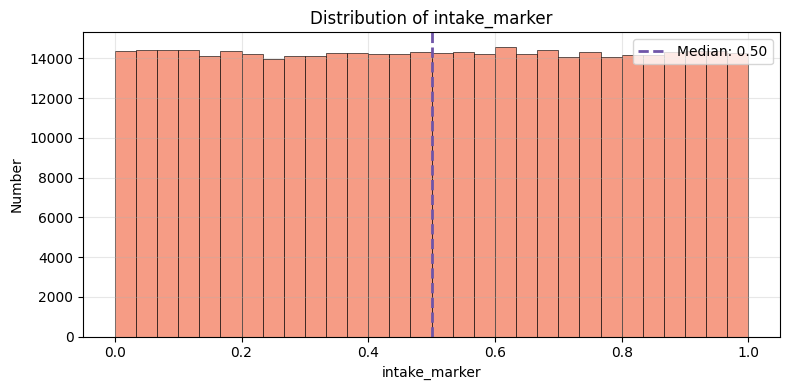

In [ ]:
intake_marker = train_df["intake_marker"].dropna()
median_intake_marker = intake_marker.median()

plt.figure(figsize=(8, 4))
plt.hist(intake_marker, bins=30, color="#F58B70", edgecolor="black", linewidth=0.5, alpha=0.85)
plt.axvline(median_intake_marker, color="#6F55A8", linestyle="--", linewidth=2,
            label=f"Median: {median_intake_marker:.2f}")
plt.xlabel("intake_marker")
plt.ylabel("Number")
plt.title("Distribution of intake_marker")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
train_df[['learner_age', 'study_minutes', 'study_time', 'attendance_rate', 'sleep_duration', 'engagement_index', 'intake_marker', 'assessment_score']].corr()

,learner_age,study_minutes,study_time,attendance_rate,sleep_duration,engagement_index,intake_marker,assessment_score
learner_age,1.000000,0.007487,0.007165,0.005810,0.004440,0.008395,0.001620,0.010489
study_minutes,0.007487,1.000000,0.948471,0.087447,0.041548,0.693814,-0.000518,0.759916
study_time,0.007165,0.948471,1.000000,0.084766,0.040979,0.662555,-0.000552,0.725674
attendance_rate,0.005810,0.087447,0.084766,1.000000,0.028524,0.747718,-0.001678,0.358336
sleep_duration,0.004440,0.041548,0.040979,0.028524,1.000000,0.047375,-0.002176,0.166864
engagement_index,0.008395,0.693814,0.662555,0.747718,0.047375,1.000000,-0.001092,0.735135
intake_marker,0.001620,-0.000518,-0.000552,-0.001678,-0.002176,-0.001092,1.000000,-0.000933
assessment_score,0.010489,0.759916,0.725674,0.358336,0.166864,0.735135,-0.000933,1.000000


Найсильніше з assessment_score корелюють study_minutes (0.76), engagement_index (0.74) та study_time (0.73), помірно — attendance_rate (0.36), слабко — sleep_duration (0.17), а learner_age та intake_marker практично не мають лінійного зв'язку з target (≈ 0). Також study_minutes і study_time майже дублюють одна одну (0.95), а engagement_index сильно пов'язаний з attendance_rate (0.75) і study_minutes (0.69).

In [ ]:
train_df.groupby('rest_quality')['sleep_duration'].describe()

,count,mean,std,min,25%,50%,75%,max
rest_quality,,,,,,,,
average,135324.0,7.077392,1.727501,3.85,5.60,7.10,8.61,10.15
good,141755.0,7.121287,1.751120,3.85,5.62,7.18,8.68,10.17
poor,142271.0,7.015111,1.757327,3.85,5.48,7.04,8.58,10.18


# **Baseline**

Неможливі значення (attendance_rate > 100, study_time > 24) вважаємо помилками запису й замінюємо на NaN. Пропуски в числових ознаках заповнюємо медіаною, у категоріальних - окремою категорією "missing", після чого всі категоріальні ознаки кодуємо через OneHotEncoder. Медіани рахуємо тільки на train-фолді, щоб уникнути витоку даних.

In [20]:
train_df['study_time'] = train_df['study_time'].where(train_df['study_time'] <= 24, np.nan)
train_df['attendance_rate'] = train_df['attendance_rate'].where(train_df['attendance_rate'] <= 100, np.nan)


In [21]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

kf = KFold(n_splits = 5, shuffle = True, random_state = 42)
y = train_df["assessment_score"].values

oof_preds = np.zeros(len(y))
fold_rmse = []

for fold, (train_idx, val_idx) in enumerate(kf.split(y)):
    y_train, y_val = y[train_idx], y[val_idx]

    mean_pred = y_train.mean()
    predictions = np.full_like(y_val, fill_value=mean_pred, dtype=float)

    oof_preds[val_idx] = predictions

    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    fold_rmse.append(rmse)

    print(f"Fold {fold}: train_mean={mean_pred:.4f}, RMSE={rmse:.4f}")

oof_rmse = np.sqrt(mean_squared_error(y, oof_preds))

print(f"\nMean RMSE across folds: {np.mean(fold_rmse):.4f}")
print(f"Std RMSE across folds:  {np.std(fold_rmse):.4f}")
print(f"OOF RMSE: {oof_rmse:.4f}")


Fold 0: train_mean=62.5236, RMSE=18.9344
Fold 1: train_mean=62.4883, RMSE=18.8899
Fold 2: train_mean=62.5170, RMSE=18.9074
Fold 3: train_mean=62.4961, RMSE=18.9772
Fold 4: train_mean=62.5154, RMSE=18.8795

Mean RMSE across folds: 18.9177
Std RMSE across folds:  0.0351
OOF RMSE: 18.9177


In [ ]:
mean_prediction = train_df['assessment_score'].mean()
submission = pd.DataFrame({
    'record_id': test_df['record_id'],
    'assessment_score': mean_prediction
})

submission.head()

,record_id,assessment_score
0,1735667,62.508067
1,1622718,62.508067
2,1027542,62.508067
3,1753464,62.508067
4,1330024,62.508067


In [ ]:
submission.to_csv('submission_baseline_mean.csv', index=False)

In [ ]:
!kaggle competitions submit -c predicting-assessment-scores-hw1-ucu-ai-2026 -f submission_baseline_mean.csv -m "mean baseline"

100% 4.69M/4.69M [00:00<00:00, 17.2MB/s]
Successfully submitted to Predicting Assessment Scores | HW1 | UCU AI 2026

Test RMSE: 18.89815


# Linear Regression

In [22]:
X = train_df.drop(columns=['record_id', 'assessment_score'])
y = train_df['assessment_score'].values

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression

In [32]:
numeric_cols = ['learner_age', 'study_time', 'study_minutes', 'attendance_rate',
            'sleep_duration', 'engagement_index', 'intake_marker']
categorical_cols = ['gender_group', 'program_track', 'home_internet', 'rest_quality',
            'learning_routine', 'campus_resources', 'assessment_level',
            'registration_group']

numeric_transformer = Pipeline(steps = [('imputer', SimpleImputer(strategy='median'))])
categorical_transformer = Pipeline(steps = [('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
                                            ('onehot', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

linreg_pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', LinearRegression())
])


In [ ]:
oof_preds_linreg = np.zeros(len(y))
fold_rmse_linreg = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    linreg_pipeline.fit(X_train, y_train)
    predictions = linreg_pipeline.predict(X_val)

    oof_preds_linreg[val_idx] = predictions

    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    fold_rmse_linreg.append(rmse)

    print(f"Fold {fold}: RMSE={rmse:.4f}")

oof_rmse_linreg = np.sqrt(mean_squared_error(y, oof_preds_linreg))

print(f"\nMean RMSE (Linear Regression): {np.mean(fold_rmse_linreg):.4f}")
print(f"Std RMSE: {np.std(fold_rmse_linreg):.4f}")
print(f"OOF RMSE: {oof_rmse_linreg:.4f}")

Fold 0: RMSE=9.1869
Fold 1: RMSE=9.1590
Fold 2: RMSE=9.1635
Fold 3: RMSE=9.1631
Fold 4: RMSE=9.1664

Mean RMSE (Linear Regression): 9.1678
Std RMSE: 0.0099
OOF RMSE: 9.1678


In [ ]:
test_df['study_time'] = test_df['study_time'].where(test_df['study_time'] <= 24, np.nan)
test_df['attendance_rate'] = test_df['attendance_rate'].where(test_df['attendance_rate'] <= 100, np.nan)

test_df['program_track'] = test_df['program_track'].str.strip().str.lower()
test_df['rest_quality'] = test_df['rest_quality'].str.strip().str.lower()
test_df['learning_routine'] = test_df['learning_routine'].str.strip().str.lower()

X_test = test_df.drop(columns=['record_id'])


In [ ]:
linreg_pipeline.fit(X, y)

pred_linreg = linreg_pipeline.predict(X_test)
submission = pd.DataFrame({
    'record_id': test_df['record_id'],
    'assessment_score': pred_linreg
})

submission.head()

,record_id,assessment_score
0,1735667,43.532525
1,1622718,79.902182
2,1027542,51.202940
3,1753464,77.631272
4,1330024,59.297413


In [ ]:
submission.to_csv('submission_linreg.csv', index=False)

In [ ]:
!kaggle competitions submit -c predicting-assessment-scores-hw1-ucu-ai-2026 -f submission_linreg.csv -m "linear regression baseline"

100% 4.70M/4.70M [00:00<00:00, 21.4MB/s]
Successfully submitted to Predicting Assessment Scores | HW1 | UCU AI 2026

Test RMSE: 9.17880

In [ ]:
feature_names = linreg_pipeline.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(linreg_pipeline.named_steps["model"].coef_, index=feature_names)

print("Intercept:", linreg_pipeline.named_steps["model"].intercept_)
print(coefs.sort_values(key=abs, ascending=False).head(15))

Intercept: 7.355129223330053
cat__learning_routine_coaching         5.815163
cat__rest_quality_poor                -4.505831
cat__rest_quality_good                 4.470481
cat__campus_resources_high             3.668423
cat__campus_resources_low             -3.668406
cat__learning_routine_self-study      -3.385923
cat__learning_routine_online videos   -2.483729
num__study_time                        1.497667
cat__learning_routine_group study     -1.433522
cat__learning_routine_mixed            1.350333
num__sleep_duration                    1.327184
cat__program_track_b.sc               -0.239325
num__engagement_index                  0.238049
cat__program_track_bba                 0.216443
cat__rest_quality_average              0.187638
dtype: float64


Intercept (7.36) - передбачений score для студента з нульовими значеннями числових ознак та еталонними категоріями, тому має лише технічний зміст. Коефіцієнти вказуютю те, наскільки збільшиться score при зміні на 1 одиницю самої ознаки, до прикладу, study_time ≈ 1.5 означає, що кожна додаткова година навчання на добу підвищує очікуваний score приблизно на 1.5 бала за незмінності решти ознак. Обмеження моделі: вона припускає лише лінійні залежності, а сильно корельовані ознаки (study_time, engagement_index, attendance_rate) роблять окремі коефіцієнти нестабільними.

Валідаційний RMSE лінійної регресії становить 9.1678 проти 18.9177 константного baseline.

# Desicion Tree

Для дерева рішень замінюємо OneHotEncoder на OrdinalEncoder: дереву не потрібні окремі бінарні стовпці для кожної категорії, а ordinal-кодування не збільшує кількість ознак, завдяки чому модель навчається й обробляє дані швидше.

In [33]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeRegressor


numeric_transformer_tree = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer_tree = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

preprocessor_tree = ColumnTransformer(transformers=[
    ('num', numeric_transformer_tree, numeric_cols),
    ('cat', categorical_transformer_tree, categorical_cols)
])

tree_pipeline_initial = Pipeline(steps=[
    ("preprocess", preprocessor_tree),
    ("model", DecisionTreeRegressor())
])

In [ ]:
oof_preds_tree_initial = np.zeros(len(y))
train_fold_rmse = []
val_fold_rmse = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    tree_pipeline_initial.fit(X_train, y_train)

    train_pred = tree_pipeline_initial.predict(X_train)
    val_pred = tree_pipeline_initial.predict(X_val)

    oof_preds_tree_initial[val_idx] = val_pred

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

    train_fold_rmse.append(train_rmse)
    val_fold_rmse.append(val_rmse)
    print(f"Fold {fold}: train RMSE={train_rmse:.4f}, val RMSE={val_rmse:.4f}")

oof_rmse_tree_initial = np.sqrt(mean_squared_error(y, oof_preds_tree_initial))

print(f"\nMean train RMSE: {np.mean(train_fold_rmse):.4f}")
print(f"Mean val RMSE:   {np.mean(val_fold_rmse):.4f}")
print(f"Std val RMSE:    {np.std(val_fold_rmse):.4f}")
print(f"OOF RMSE:        {oof_rmse_tree_initial:.4f}")

Fold 0: train RMSE=0.0000, val RMSE=13.0917
Fold 1: train RMSE=0.0000, val RMSE=13.1144
Fold 2: train RMSE=0.0000, val RMSE=13.1465
Fold 3: train RMSE=0.0000, val RMSE=13.2204
Fold 4: train RMSE=0.0000, val RMSE=13.1331

Mean train RMSE: 0.0000
Mean val RMSE:   13.1412
Std val RMSE:    0.0437
OOF RMSE:        13.1413


Початкове дерево рішень (без обмежень) має train RMSE = 0 і val RMSE = 13.14, тобто воно повністю перенавчилось: запам'ятало train-дані разом із шумом і гірше узагальнюється. Воно все ж краще за константний baseline (18.92), але програє лінійній регресії (9.17). Покращити його можна обмеженням складності (max_depth, min_samples_leaf).

## Підбір гіперпараметрів

In [ ]:
max_depth_values = [2, 4, 6, 8, 10, 12, 14]

results = []

for depth in max_depth_values:
    tree_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor_tree),
        ('model', DecisionTreeRegressor(max_depth=depth, random_state=42))
    ])

    train_rmse_list = []
    val_rmse_list = []

    for train_idx, val_idx in kf.split(X):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        tree_pipeline.fit(X_train, y_train)

        train_pred = tree_pipeline.predict(X_train)
        val_pred = tree_pipeline.predict(X_val)

        train_rmse_list.append(np.sqrt(mean_squared_error(y_train, train_pred)))
        val_rmse_list.append(np.sqrt(mean_squared_error(y_val, val_pred)))

    results.append({
        'max_depth': depth,
        'train_rmse': np.mean(train_rmse_list),
        'val_rmse': np.mean(val_rmse_list)
    })

    print(f"max_depth={depth}: train RMSE={np.mean(train_rmse_list):.4f}, val RMSE={np.mean(val_rmse_list):.4f}")

results_df = pd.DataFrame(results)

max_depth=2: train RMSE=12.9117, val RMSE=12.9274
max_depth=4: train RMSE=11.4249, val RMSE=11.4403
max_depth=6: train RMSE=10.5870, val RMSE=10.6110
max_depth=8: train RMSE=9.9853, val RMSE=10.0572
max_depth=10: train RMSE=9.4943, val RMSE=9.7177
max_depth=12: train RMSE=8.9837, val RMSE=9.6534
max_depth=14: train RMSE=8.2744, val RMSE=10.0401


Обмеження глибини суттєво покращило дерево: val RMSE впав із 13.14 (без обмежень) до 9.65 при max_depth=12. При малій глибині (2-6) дерево недонавчене (train і val RMSE близькі, але високі), а при max_depth=14 val RMSE знову зростає (10.04) при продовженні падіння train RMSE (8.27), що свідчить про початок перенавчання. Найкраще дерево (9.65) все ще трохи поступається лінійній регресії (9.17).

In [ ]:
max_depth_values = [9, 10, 11, 12, 13]
min_samples_leaf_values = [5, 10, 20, 50, 70, 100]

for depth in max_depth_values:
  for leaf in min_samples_leaf_values:
    tree_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor_tree),
        ('model', DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=42))
    ])

    train_rmse_list = []
    val_rmse_list = []

    for train_idx, val_idx in kf.split(X):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        tree_pipeline.fit(X_train, y_train)

        train_pred = tree_pipeline.predict(X_train)
        val_pred = tree_pipeline.predict(X_val)

        train_rmse_list.append(np.sqrt(mean_squared_error(y_train, train_pred)))
        val_rmse_list.append(np.sqrt(mean_squared_error(y_val, val_pred)))

    print(f"max_depth={depth}, min_samples_leaf={leaf}: train RMSE={np.mean(train_rmse_list):.4f}, val RMSE={np.mean(val_rmse_list):.4f}")

max_depth=9, min_samples_leaf=5: train RMSE=9.7341, val RMSE=9.8580
max_depth=9, min_samples_leaf=10: train RMSE=9.7343, val RMSE=9.8577
max_depth=9, min_samples_leaf=20: train RMSE=9.7348, val RMSE=9.8574
max_depth=9, min_samples_leaf=50: train RMSE=9.7378, val RMSE=9.8562
max_depth=9, min_samples_leaf=70: train RMSE=9.7400, val RMSE=9.8554
max_depth=9, min_samples_leaf=100: train RMSE=9.7435, val RMSE=9.8538
max_depth=10, min_samples_leaf=5: train RMSE=9.4952, val RMSE=9.7140
max_depth=10, min_samples_leaf=10: train RMSE=9.4967, val RMSE=9.7121
max_depth=10, min_samples_leaf=20: train RMSE=9.5001, val RMSE=9.7101
max_depth=10, min_samples_leaf=50: train RMSE=9.5109, val RMSE=9.7061
max_depth=10, min_samples_leaf=70: train RMSE=9.5187, val RMSE=9.7039
max_depth=10, min_samples_leaf=100: train RMSE=9.5297, val RMSE=9.7023
max_depth=11, min_samples_leaf=5: train RMSE=9.2542, val RMSE=9.6300
max_depth=11, min_samples_leaf=10: train RMSE=9.2608, val RMSE=9.6227
max_depth=11, min_samples_l

Додавання min_samples_leaf покращило дерево: найкращі параметри max_depth=13, min_samples_leaf=100 дають val RMSE = 9.50 проти 9.65 при обмеженні лише глибини. Більші значення min_samples_leaf зменшують перенавчання (розрив між train і val RMSE для глибини 13 скорочується з ≈ 1.02 при leaf=5 до ≈ 0.35 при leaf=100) і дозволяють глибшому дереву узагальнюватись краще. Втім, навіть найкраще дерево поступається лінійній регресії.

In [ ]:
import time

tree_pipeline_tuned = Pipeline(steps=[
    ('preprocessor', preprocessor_tree),
    ('model', DecisionTreeRegressor(max_depth=13, min_samples_leaf=100, random_state=42))
])

oof_preds_tree_tuned = np.zeros(len(y))
train_fold_rmse = []
val_fold_rmse = []

start_time = time.time()

for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    tree_pipeline_tuned.fit(X_train, y_train)

    train_pred = tree_pipeline_tuned.predict(X_train)
    val_pred = tree_pipeline_tuned.predict(X_val)

    oof_preds_tree_tuned[val_idx] = val_pred

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

    train_fold_rmse.append(train_rmse)
    val_fold_rmse.append(val_rmse)

    print(f"Fold {fold}: train RMSE={train_rmse:.4f}, val RMSE={val_rmse:.4f}")

tree_tuned_time = time.time() - start_time

oof_rmse_tree_tuned = np.sqrt(mean_squared_error(y, oof_preds_tree_tuned))

print(f"\nMean train RMSE: {np.mean(train_fold_rmse):.4f}")
print(f"Mean val RMSE:   {np.mean(val_fold_rmse):.4f}")
print(f"Std val RMSE:    {np.std(val_fold_rmse):.4f}")
print(f"OOF RMSE:        {oof_rmse_tree_tuned:.4f}")
print(f"Training time (5 folds): {tree_tuned_time:.1f}s")

Fold 0: train RMSE=9.1547, val RMSE=9.5340
Fold 1: train RMSE=9.1620, val RMSE=9.4923
Fold 2: train RMSE=9.1538, val RMSE=9.4920
Fold 3: train RMSE=9.1618, val RMSE=9.4989
Fold 4: train RMSE=9.1534, val RMSE=9.5012

Mean train RMSE: 9.1571
Mean val RMSE:   9.5036
Std val RMSE:    0.0156
OOF RMSE:        9.5037
Training time (5 folds): 30.1s


# Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline_initial = Pipeline(steps=[
    ('preprocessor', preprocessor_tree),
    ('model', RandomForestRegressor(n_estimators=10, max_depth=12, random_state=42, n_jobs=-1))
])

In [ ]:
oof_preds_rf_initial = np.zeros(len(y))
rmse_rf_initial_train = []
rmse_rf_initial_val = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    rf_pipeline_initial.fit(X_train, y_train)

    train_pred = rf_pipeline_initial.predict(X_train)
    val_pred = rf_pipeline_initial.predict(X_val)

    oof_preds_rf_initial[val_idx] = val_pred

    rmse_train = np.sqrt(mean_squared_error(y_train, train_pred))
    rmse_val = np.sqrt(mean_squared_error(y_val, val_pred))

    rmse_rf_initial_train.append(rmse_train)
    rmse_rf_initial_val.append(rmse_val)

    print(f"Fold {fold}: train RMSE={rmse_train:.4f}, val RMSE={rmse_val:.4f}")

oof_rmse_rf_initial = np.sqrt(mean_squared_error(y, oof_preds_rf_initial))

print(f"\nMean train RMSE: {np.mean(rmse_rf_initial_train):.4f}")
print(f"Mean val RMSE:   {np.mean(rmse_rf_initial_val):.4f}")
print(f"Std val RMSE:    {np.std(rmse_rf_initial_val):.4f}")
print(f"OOF RMSE:        {oof_rmse_rf_initial:.4f}")

Fold 0: train RMSE=8.7025, val RMSE=9.2902
Fold 1: train RMSE=8.6899, val RMSE=9.2361
Fold 2: train RMSE=8.6921, val RMSE=9.2506
Fold 3: train RMSE=8.6883, val RMSE=9.2504
Fold 4: train RMSE=8.7000, val RMSE=9.2594

Mean train RMSE: 8.6946
Mean val RMSE:   9.2573
Std val RMSE:    0.0181
OOF RMSE:        9.2574


Початковий random forest краще за tuned Desicion Tree: val RMSE = 9.26 проти 9.50

Усереднення дерев зменшує дисперсію: кожне дерево по-різному перенавчається на своїй bootstrap-вибірці й підмножині ознак, а усереднення згладжує ці помилки.

## Підбір гіперпараметрів

In [ ]:
n_estimators_values = [50, 100, 200]

results_rf_n = []

for n_est in n_estimators_values:
    rf_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor_tree),
        ('model', RandomForestRegressor(n_estimators=n_est, max_depth=12,
                                          random_state=42, n_jobs=-1))
    ])

    train_rmse_list = []
    val_rmse_list = []

    for train_idx, val_idx in kf.split(X):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        rf_pipeline.fit(X_train, y_train)

        train_pred = rf_pipeline.predict(X_train)
        val_pred = rf_pipeline.predict(X_val)

        train_rmse_list.append(np.sqrt(mean_squared_error(y_train, train_pred)))
        val_rmse_list.append(np.sqrt(mean_squared_error(y_val, val_pred)))

    results_rf_n.append({
        'n_estimators': n_est,
        'train_rmse': np.mean(train_rmse_list),
        'val_rmse': np.mean(val_rmse_list),
        'gap': np.mean(val_rmse_list) - np.mean(train_rmse_list)
    })

    print(f"n_estimators={n_est}: train RMSE={np.mean(train_rmse_list):.4f}, val RMSE={np.mean(val_rmse_list):.4f}")

results_rf_n_df = pd.DataFrame(results_rf_n)
print(results_rf_n_df)

n_estimators=50: train RMSE=8.6367, val RMSE=9.1986
n_estimators=100: train RMSE=8.6282, val RMSE=9.1904
n_estimators=200: train RMSE=8.6243, val RMSE=9.1862
   n_estimators  train_rmse  val_rmse       gap
0            50    8.636717  9.198565  0.561848
1           100    8.628237  9.190359  0.562121
2           200    8.624343  9.186222  0.561879


Обрано n_estimators=50 замість більших значень (100, 200), оскільки подальше збільшення дає лише мінімальне покращення val RMSE, що не виправдовує пропорційне зростання часу навчання.

Результат 9.199 вийшов кращим за початкові налаштування 9.257

In [ ]:
max_depth_values = [10, 13, 16, 20]

results_rf_depth = []

for depth in max_depth_values:
    rf_pipeline = Pipeline(steps=[
        ('preprocess', preprocessor_tree),
        ('model', RandomForestRegressor(n_estimators=50, max_depth=depth,
                                          random_state=42, n_jobs=-1))
    ])

    train_rmse_list = []
    val_rmse_list = []

    for train_idx, val_idx in kf.split(X):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        rf_pipeline.fit(X_train, y_train)

        train_pred = rf_pipeline.predict(X_train)
        val_pred = rf_pipeline.predict(X_val)

        train_rmse_list.append(np.sqrt(mean_squared_error(y_train, train_pred)))
        val_rmse_list.append(np.sqrt(mean_squared_error(y_val, val_pred)))

    results_rf_depth.append({
        'max_depth': depth,
        'train_rmse': np.mean(train_rmse_list),
        'val_rmse': np.mean(val_rmse_list),
        'gap': np.mean(val_rmse_list) - np.mean(train_rmse_list)
    })

    print(f"max_depth={depth}: train RMSE={np.mean(train_rmse_list):.4f}, val RMSE={np.mean(val_rmse_list):.4f}")

max_depth=10: train RMSE=9.1891, val RMSE=9.3848
max_depth=13: train RMSE=8.2750, val RMSE=9.1627
max_depth=16: train RMSE=6.7446, val RMSE=9.1719
max_depth=20: train RMSE=4.6531, val RMSE=9.2356


Підбір max_depth показав оптимум при глибині 13 (val RMSE = 9.163): при глибині 10 ліс недонавчений (val RMSE = 9.38), а при 16-20 перенавчається. Найкращий ліс практично зрівнявся з лінійною регресією (9.168)

In [ ]:
max_features_values = ['sqrt', 0.5, 0.7, 1.0]

results_rf_features = []

for feat in max_features_values:
    rf_pipeline = Pipeline(steps=[
        ('preprocess', preprocessor_tree),
        ('model', RandomForestRegressor(n_estimators=50, max_depth=13,
                                          max_features=feat,
                                          random_state=42, n_jobs=-1))
    ])

    train_rmse_list = []
    val_rmse_list = []

    for train_idx, val_idx in kf.split(X):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        rf_pipeline.fit(X_train, y_train)

        train_pred = rf_pipeline.predict(X_train)
        val_pred = rf_pipeline.predict(X_val)

        train_rmse_list.append(np.sqrt(mean_squared_error(y_train, train_pred)))
        val_rmse_list.append(np.sqrt(mean_squared_error(y_val, val_pred)))

    results_rf_features.append({
        'max_features': feat,
        'train_rmse': np.mean(train_rmse_list),
        'val_rmse': np.mean(val_rmse_list)
    })

    print(f"max_features={feat}: train RMSE={np.mean(train_rmse_list):.4f}, val RMSE={np.mean(val_rmse_list):.4f}")

max_features=sqrt: train RMSE=8.6555, val RMSE=9.2630
max_features=0.5: train RMSE=8.3667, val RMSE=9.1401
max_features=0.7: train RMSE=8.3110, val RMSE=9.1443
max_features=1.0: train RMSE=8.2750, val RMSE=9.1627


In [ ]:
import time
from sklearn.ensemble import RandomForestRegressor

rf_pipeline_final = Pipeline(steps=[
    ('preprocessor', preprocessor_tree),
    ('model', RandomForestRegressor(n_estimators=50, max_depth=13, max_features=0.5,
                                      random_state=42, n_jobs=-1))
])

oof_preds_rf_final = np.zeros(len(y))
train_fold_rmse_rf = []
val_fold_rmse_rf = []

start_time = time.time()

for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    rf_pipeline_final.fit(X_train, y_train)

    train_pred = rf_pipeline_final.predict(X_train)
    val_pred = rf_pipeline_final.predict(X_val)

    oof_preds_rf_final[val_idx] = val_pred

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

    train_fold_rmse_rf.append(train_rmse)
    val_fold_rmse_rf.append(val_rmse)

    print(f"Fold {fold}: train RMSE={train_rmse:.4f}, val RMSE={val_rmse:.4f}")

rf_final_time = time.time() - start_time

oof_rmse_rf_final = np.sqrt(mean_squared_error(y, oof_preds_rf_final))

print(f"\nMean train RMSE: {np.mean(train_fold_rmse_rf):.4f}")
print(f"Mean val RMSE:   {np.mean(val_fold_rmse_rf):.4f}")
print(f"Std val RMSE:    {np.std(val_fold_rmse_rf):.4f}")
print(f"OOF RMSE:        {oof_rmse_rf_final:.4f}")
print(f"Training time (5-fold CV): {rf_final_time:.1f}s")

Fold 0: train RMSE=8.3655, val RMSE=9.1612
Fold 1: train RMSE=8.3692, val RMSE=9.1239
Fold 2: train RMSE=8.3691, val RMSE=9.1382
Fold 3: train RMSE=8.3671, val RMSE=9.1464
Fold 4: train RMSE=8.3628, val RMSE=9.1307

Mean train RMSE: 8.3667
Mean val RMSE:   9.1401
Std val RMSE:    0.0130
OOF RMSE:        9.1401
Training time (5-fold CV): 235.9s


Для random forest ми підібрали n_estimators = 50, max_depth=13 та max_features=0.5. Фінальна модель дає val RMSE = 9.14, що краще за tuned Desicion Tree (9.50). Ціною є час навчання: 5-fold CV для лісу триває 235.9с проти 30.1с для одного дерева.

In [ ]:
rf_pipeline_final.fit(X, y)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['learner_age', 'study_time',
                                                   'study_minutes',
                                                   'attendance_rate',
                                                   'sleep_duration',
                                                   'engagement_index',
                                                   'intake_marker']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('ordinal',
                                                                   OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['gender_group',
                                                   'program_track',
                                                   'home_internet',
                                                   'rest_quality',
                                                   'learning_routine',
                                                   'campus_resources',
                                                   'assessment_level',
                                                   'registration_group'])])),
                ('model',
                 RandomForestRegressor(max_depth=13, max_features=0.5,
                                       n_estimators=50, n_jobs=-1,
                                       random_state=42))])

In [ ]:
test_predictions = rf_pipeline_final.predict(X_test)

In [ ]:
submission = pd.DataFrame({
    'record_id': test_df['record_id'],
    'assessment_score': test_predictions
})

submission.head()

,record_id,assessment_score
0,1735667,42.903183
1,1622718,78.550243
2,1027542,47.735498
3,1753464,80.331706
4,1330024,59.565888


In [ ]:
submission.to_csv('submission_random_forest_tuned.csv', index=False)

In [ ]:
!kaggle competitions submit -c predicting-assessment-scores-hw1-ucu-ai-2026 -f submission_random_forest_tuned.csv -m "random forest tuned"

100% 4.69M/4.69M [00:00<00:00, 10.6MB/s]
Successfully submitted to Predicting Assessment Scores | HW1 | UCU AI 2026

Test RMSE: 9.14881

# XGBoost

In [34]:
import xgboost as xgb

numeric_transformer_boost = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer_boost = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_boost = ColumnTransformer(transformers=[
    ('num', numeric_transformer_boost, numeric_cols),
    ('cat', categorical_transformer_boost, categorical_cols)
])

In [ ]:
xgb_pipeline_initial = Pipeline(steps=[
    ('preprocess', preprocessor_boost),
    ('model', xgb.XGBRegressor(random_state=42, n_jobs=-1))
])

oof_preds_xgb_initial = np.zeros(len(y))
train_rmse_list = []
val_rmse_list = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    xgb_pipeline_initial.fit(X_train, y_train)

    train_pred = xgb_pipeline_initial.predict(X_train)
    val_pred = xgb_pipeline_initial.predict(X_val)

    oof_preds_xgb_initial[val_idx] = val_pred

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

    train_rmse_list.append(train_rmse)
    val_rmse_list.append(val_rmse)

    print(f"Fold {fold}: train RMSE={train_rmse:.4f}, val RMSE={val_rmse:.4f}")

oof_rmse_xgb_initial = np.sqrt(mean_squared_error(y, oof_preds_xgb_initial))

print(f"\nMean train RMSE: {np.mean(train_rmse_list):.4f}")
print(f"Mean val RMSE:   {np.mean(val_rmse_list):.4f}")
print(f"Std val RMSE:    {np.std(val_rmse_list):.4f}")
print(f"OOF RMSE:        {oof_rmse_xgb_initial:.4f}")

Fold 0: train RMSE=8.7264, val RMSE=9.0115
Fold 1: train RMSE=8.7482, val RMSE=8.9982
Fold 2: train RMSE=8.7365, val RMSE=8.9944
Fold 3: train RMSE=8.7360, val RMSE=9.0031
Fold 4: train RMSE=8.7327, val RMSE=9.0113

Mean train RMSE: 8.7360
Mean val RMSE:   9.0037
Std val RMSE:    0.0069
OOF RMSE:        9.0037


XGBoost краще за налаштований random forest: val RMSE = 9.004 проти 9.140.

Ліс усереднює незалежні глибокі дерева, а бустинг будує неглибокі дерева послідовно, і кожне виправляє помилки попередніх. Тому він ефективніше вловлює і лінійну залежність, і дрібні нелінійності та взаємодії, які ліс наближає ступінчасто.

In [ ]:
xgb_pipeline_initial.fit(X, y)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['learner_age', 'study_time',
                                                   'study_minutes',
                                                   'attendance_rate',
                                                   'sleep_duration',
                                                   'engagement_index',
                                                   'intake_marker']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   O...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=None, n_jobs=-1,
                              num_parallel_tree=None, ...))])

In [ ]:
test_predictions = xgb_pipeline_initial.predict(X_test)

submission = pd.DataFrame({
    'record_id': test_df['record_id'],
    'assessment_score': test_predictions
})

display(submission.head())

submission.to_csv('submission_xgb_initial.csv', index=False)

,record_id,assessment_score
0,1735667,40.037708
1,1622718,77.039581
2,1027542,49.607025
3,1753464,78.993767
4,1330024,59.034077


In [ ]:
!kaggle competitions submit -c predicting-assessment-scores-hw1-ucu-ai-2026 -f submission_xgb_initial.csv -m "xgboost initial"

100% 3.13M/3.13M [00:01<00:00, 2.79MB/s]
Successfully submitted to Predicting Assessment Scores | HW1 | UCU AI 2026

Test RMSE: 9.00630

## Підбір гіперпараметрів

**Діапазон пошуку.** Підбирали learning_rate ∈ {0.3, 0.1, 0.05, 0.03}, max_depth ∈ {3, 4, 6, 8}. Оптимальну кількість дерев визначає рання зупинка.

**Дані для ранньої зупинки.** У кожному з 5 фолдів CV із train-частини випадково виділяємо 10% (eval set), навчаємо модель на решті 90% і зупиняємося, коли RMSE на eval set не покращується 50 ітерацій поспіль. Валідаційний фолд при цьому не використовується для вибору точки зупинки, тому оцінка якості на ньому не містить витоку.

**Вибрані параметри.** learning_rate = 0.05, max_depth = 4, n_estimators = 1345.

**Результати валідації.** Mean val RMSE = 8.9397, що краще за початковий XGBoost (9.004) і random forest (9.140).


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split

def cv_xgb(params, X, y, kf, prep, max_rounds=3000, rounds=50, use_gpu=False):
    train_rmse_list = []
    val_rmse_list = []
    best_rounds_list = []
    oof_preds = np.zeros(len(y))

    for train_idx, val_idx in kf.split(X):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        p = clone(prep)
        X_train_prep = p.fit_transform(X_train)
        X_val_prep = p.transform(X_val)

        X_fit, X_eval, y_fit, y_eval = train_test_split(X_train_prep, y_train, test_size=0.1, random_state=42)

        model_params = {'device': 'cuda', 'tree_method': 'hist'} if use_gpu else {'tree_method': 'hist'}
        model = xgb.XGBRegressor(n_estimators=max_rounds, early_stopping_rounds=rounds,
                                   random_state=42, n_jobs=-1, **model_params, **params)
        model.fit(X_fit, y_fit, eval_set=[(X_eval, y_eval)], verbose=False)

        train_pred = model.predict(X_train_prep)
        val_pred = model.predict(X_val_prep)

        oof_preds[val_idx] = val_pred

        train_rmse_list.append(np.sqrt(mean_squared_error(y_train, train_pred)))
        val_rmse_list.append(np.sqrt(mean_squared_error(y_val, val_pred)))
        best_rounds_list.append(model.best_iteration + 1)

    oof_rmse = np.sqrt(mean_squared_error(y, oof_preds))

    return {
        'train_rmse': np.mean(train_rmse_list),
        'val_rmse': np.mean(val_rmse_list),
        'std_val_rmse': np.std(val_rmse_list),
        'oof_rmse': oof_rmse,
        'best_rounds': int(np.mean(best_rounds_list)),
        'oof_preds': oof_preds
    }

In [ ]:
learning_rate_values = [0.3, 0.1, 0.05, 0.03]
results_xgb_lr = []

for lr in learning_rate_values:
    res = cv_xgb({'learning_rate': lr}, X, y, kf, preprocessor_boost)

    results_xgb_lr.append({
        'learning_rate': lr,
        'train_rmse': res['train_rmse'],
        'val_rmse': res['val_rmse'],
        'best_rounds': res['best_rounds']
    })

    print(f"learning_rate={lr}: train RMSE={res['train_rmse']:.4f}, val RMSE={res['val_rmse']:.4f}, rounds={res['best_rounds']}")

results_xgb_lr_df = pd.DataFrame(results_xgb_lr).sort_values('val_rmse')
print(results_xgb_lr_df)

learning_rate=0.3: train RMSE=8.8116, val RMSE=9.0070, rounds=70
learning_rate=0.1: train RMSE=8.7039, val RMSE=8.9514, rounds=280
learning_rate=0.05: train RMSE=8.7017, val RMSE=8.9424, rounds=536
learning_rate=0.03: train RMSE=8.7088, val RMSE=8.9395, rounds=853
   learning_rate  train_rmse  val_rmse  best_rounds
3           0.03    8.708845  8.939519          853
2           0.05    8.701671  8.942365          536
1           0.10    8.703924  8.951356          280
0           0.30    8.811597  9.006997           70


In [ ]:
best_lr = 0.05
max_depth_values = [3, 4, 6, 8]

results_xgb_depth = []

for depth in max_depth_values:
    res = cv_xgb({'learning_rate': best_lr, 'max_depth': depth}, X, y, kf, preprocessor_boost, use_gpu=True)

    results_xgb_depth.append({
        'max_depth': depth,
        'train_rmse': res['train_rmse'],
        'val_rmse': res['val_rmse'],
        'best_rounds': res['best_rounds']
    })

    print(f"max_depth={depth}: train RMSE={res['train_rmse']:.4f}, val RMSE={res['val_rmse']:.4f}, rounds={res['best_rounds']}")

results_xgb_depth_df = pd.DataFrame(results_xgb_depth).sort_values('val_rmse')
print(results_xgb_depth_df)

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [08:17:30] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


max_depth=3: train RMSE=8.8643, val RMSE=8.9417, rounds=2191
max_depth=4: train RMSE=8.8119, val RMSE=8.9397, rounds=1345
max_depth=6: train RMSE=8.7017, val RMSE=8.9424, rounds=536
max_depth=8: train RMSE=8.4932, val RMSE=8.9526, rounds=296
   max_depth  train_rmse  val_rmse  best_rounds
1          4    8.811899  8.939669         1345
0          3    8.864257  8.941727         2191
2          6    8.701674  8.942353          536
3          8    8.493236  8.952558          296


In [ ]:
best_rounds_final = 1345

xgb_pipeline_final = Pipeline(steps=[
    ('preprocess', preprocessor_boost),
    ('model', xgb.XGBRegressor(
        learning_rate=0.05,
        max_depth=4,
        n_estimators=int(best_rounds_final * 1.1),
        random_state=42,
        n_jobs=-1
    ))
])

xgb_pipeline_final.fit(X, y)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['learner_age', 'study_time',
                                                   'study_minutes',
                                                   'attendance_rate',
                                                   'sleep_duration',
                                                   'engagement_index',
                                                   'intake_marker']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   O...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=4, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=1479, n_jobs=-1,
                              num_parallel_tree=None, ...))])

In [ ]:
test_predictions = xgb_pipeline_final.predict(X_test)

In [ ]:
submission = pd.DataFrame({
    'record_id': test_df['record_id'],
    'assessment_score': test_predictions
})

submission.head()

,record_id,assessment_score
0,1735667,43.819935
1,1622718,77.640167
2,1027542,51.341022
3,1753464,80.341248
4,1330024,59.871044


In [ ]:
submission.to_csv('submission_xgb_tuned.csv', index=False)

In [ ]:
!kaggle competitions submit -c predicting-assessment-scores-hw1-ucu-ai-2026 -f submission_xgb_tuned.csv -m "xgboost tuned"

100% 3.13M/3.13M [00:00<00:00, 3.73MB/s]
Successfully submitted to Predicting Assessment Scores | HW1 | UCU AI 2026

Test RMSE: 8.94205.

# Feature Engineering

In [ ]:
importances = xgb_pipeline_final.named_steps['model'].feature_importances_
feature_names = xgb_pipeline_final.named_steps['preprocess'].get_feature_names_out()
pd.Series(importances, index=feature_names).sort_values(ascending=False)

,0
num__study_minutes,0.146120
cat__rest_quality_good,0.133596
cat__learning_routine_coaching,0.125036
cat__rest_quality_poor,0.123739
num__study_time,0.090564
cat__campus_resources_low,0.088659
cat__campus_resources_high,0.081147
num__engagement_index,0.077108
cat__learning_routine_mixed,0.032492
cat__learning_routine_self-study,0.030736


### Дроп слабких фіч

За важливістю ознак XGBoost видно дві групи: суттєвий внесок дають study_minutes (0.146), rest_quality, learning_routine, campus_resources, study_time та engagement_index, тоді як решта ознак (registration_group, assessment_level, home_internet, gender_group, program_track, learner_age, intake_marker мають важливість ≈ 0.0005, тобто на рівні шуму.

Видалення слабких ознак дало незначне покращення з 8.9397 до 8.936.

In [ ]:
weak_features = ['intake_marker', 'registration_group', 'assessment_level', 'home_internet']

num_cols_dropped = [c for c in numeric_cols if c not in weak_features]
cat_cols_dropped = [c for c in categorical_cols if c not in weak_features]

print("Числові, що лишились:", num_cols_dropped)
print("Категоріальні, що лишились:", cat_cols_dropped)

X_dropped = X[num_cols_dropped + cat_cols_dropped]

preprocessor_boost_dropped = ColumnTransformer(transformers=[
    ('num', numeric_transformer_boost, num_cols_dropped),
    ('cat', categorical_transformer_boost, cat_cols_dropped)
])

Числові, що лишились: ['learner_age', 'study_time', 'study_minutes', 'attendance_rate', 'sleep_duration', 'engagement_index']
Категоріальні, що лишились: ['gender_group', 'program_track', 'rest_quality', 'learning_routine', 'campus_resources']


In [ ]:
xgb_params_ref = {'learning_rate': 0.05, 'max_depth': 4}

res_dropped = cv_xgb(xgb_params_ref, X_dropped, y, kf, preprocessor_boost_dropped, use_gpu=True)
print(f"Після дропу слабких фіч:")
print(f"  Mean train RMSE: {res_dropped['train_rmse']:.4f}")
print(f"  Mean val RMSE:   {res_dropped['val_rmse']:.4f}")
print(f"  Std val RMSE:    {res_dropped['std_val_rmse']:.4f}")
print(f"  OOF RMSE:        {res_dropped['oof_rmse']:.4f}")
print(f"  Best rounds:     {res_dropped['best_rounds']}")

Числові, що лишились: ['learner_age', 'study_time', 'study_minutes', 'attendance_rate', 'sleep_duration', 'engagement_index']
Категоріальні, що лишились: ['gender_group', 'program_track', 'rest_quality', 'learning_routine', 'campus_resources']


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [08:28:58] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Після дропу слабких фіч:
  Mean train RMSE: 8.8147
  Mean val RMSE:   8.9355
  Std val RMSE:    0.0096
  OOF RMSE:        8.9355
  Best rounds:     1419


### Експеримент із study_minutes/time

Далі спробувала отримати чистішу колонку study_minutes: пропуски заповнювала значеннями study_time * 60 там, де study_time лежить у розумних межах (<10год). Проте результат погіршився (val RMSE = 8.9797 проти 8.936). Ймовірні причини: відновлені значення не додають нової інформації, бо study_time уже є окремою ознакою; кореляція між колонками становить 0.95, а не 1, тому study_time * 60 лише наближає справжні хвилини, і колонка стає сумішшю значень різної точності. Тому цей підхід відкинула й повернулась до попередньої версії ознак.

In [ ]:
X_study_merged = X_dropped.copy()

study_time_clean = X['study_time'].where(X['study_time'] <= 9, np.nan)
X_study_merged['study_minutes_final'] = X['study_minutes'].fillna(study_time_clean * 60)

X_study_merged = X_study_merged.drop(columns=['study_minutes', 'study_time'])

print(X_study_merged.columns.tolist())

['learner_age', 'attendance_rate', 'sleep_duration', 'engagement_index', 'gender_group', 'program_track', 'rest_quality', 'learning_routine', 'campus_resources', 'study_minutes_final']


In [ ]:
num_cols_merged = [c for c in num_cols_dropped if c not in ['study_time', 'study_minutes']] + ['study_minutes_final']
cat_cols_merged = cat_cols_dropped

preprocessor_boost_merged = ColumnTransformer(transformers=[
    ('num', numeric_transformer_boost, num_cols_merged),
    ('cat', categorical_transformer_boost, cat_cols_merged)
])

X_study_merged = X_study_merged[num_cols_merged + cat_cols_merged]
X_study_merged.columns

Index(['learner_age', 'attendance_rate', 'sleep_duration', 'engagement_index',
       'study_minutes_final', 'gender_group', 'program_track', 'rest_quality',
       'learning_routine', 'campus_resources'],
      dtype='object')

In [ ]:
res_study_merged = cv_xgb({'learning_rate': 0.05, 'max_depth': 4},
                               X_study_merged, y, kf, preprocessor_boost_merged, use_gpu=True)

print(f"Після об'єднання study_minutes_final::")
print(f"  Mean train RMSE: {res_study_merged['train_rmse']:.4f}")
print(f"  Mean val RMSE:   {res_study_merged['val_rmse']:.4f}")
print(f"  Std val RMSE:    {res_study_merged['std_val_rmse']:.4f}")
print(f"  OOF RMSE:        {res_study_merged['oof_rmse']:.4f}")
print(f"  Best rounds:     {res_study_merged['best_rounds']}")

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [07:56:44] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Після об'єднання study_minutes_final::
  Mean train RMSE: 8.8912
  Mean val RMSE:   8.9797
  Std val RMSE:    0.0106
  OOF RMSE:        8.9797
  Best rounds:     1002


### Додавання нових взаємодій

Далі додала три ознаки-взаємодії: weighted_study (study_minutes × attendance_rate), weighted_time (study_time × attendance_rate) та study_efficiency (study_minutes / sleep_duration). Вибір ознак ґрунтується на важливості: study_minutes і attendance_rate (разом з engagement_index) несуть основний сигнал. Val RMSE покращився з 8.936 до 8.9298.

In [ ]:
X_interact = X_dropped.copy()

X_interact['weighted_study'] = X_interact['study_minutes'] * X_interact['attendance_rate']
X_interact['weighted_time'] = X_interact['study_time'] * X_interact['attendance_rate']
X_interact['study_efficiency'] = X_interact['study_minutes'] / X_interact['sleep_duration']

In [ ]:
num_cols_interact = num_cols_dropped + ['weighted_study', 'study_efficiency', 'weighted_time']

preprocessor_boost_interact = ColumnTransformer(transformers=[
    ('num', numeric_transformer_boost, num_cols_interact),
    ('cat', categorical_transformer_boost, cat_cols_dropped)
])

X_interact = X_interact[num_cols_interact + cat_cols_dropped]

In [ ]:
res_interact = cv_xgb({'learning_rate': 0.05, 'max_depth': 4},
                          X_interact, y, kf, preprocessor_boost_interact, use_gpu=True)

print(f"З новими взаємодіям:")
print(f"  Mean train RMSE: {res_interact['train_rmse']:.4f}")
print(f"  Mean val RMSE:   {res_interact['val_rmse']:.4f}")
print(f"  Std val RMSE:    {res_interact['std_val_rmse']:.4f}")
print(f"  OOF RMSE:        {res_interact['oof_rmse']:.4f}")
print(f"  Best rounds:     {res_interact['best_rounds']}")

З новими взаємодіям:
  Mean train RMSE: 8.8082
  Mean val RMSE:   8.9298
  Std val RMSE:    0.0096
  OOF RMSE:        8.9298
  Best rounds:     1332


### Додавання взаємодій категорій

Далі додала два бінарні прапорці для комбінацій найсильніших категоріальних ознак: good_conditions (rest_quality = good, learning_routine = coaching, campus_resources = high) та bad_conditions (poor, self-study, low). Val RMSE змінився з 8.9298 до 8.9293, тобто практично не покращився. Імовірно, глибоке дерево вже саме будує ці комбінації, а самі групи нечисленні, тому прапорці не додають нової інформації.

In [ ]:
X_flags = X_interact.copy()

X_flags['good_conditions'] = (
    (X['rest_quality'] == 'good') &
    (X['learning_routine'] == 'coaching') &
    (X['campus_resources'] == 'high')
).astype(int)

X_flags['bad_conditions'] = (
    (X['rest_quality'] == 'poor') &
    (X['learning_routine'] == 'self-study') &
    (X['campus_resources'] == 'low')
).astype(int)

In [ ]:
num_cols_flags = num_cols_interact + ['good_conditions', 'bad_conditions']

preprocessor_boost_flags = ColumnTransformer(transformers=[
    ('num', numeric_transformer_boost, num_cols_flags),
    ('cat', categorical_transformer_boost, cat_cols_dropped)
])

X_flags = X_flags[num_cols_flags + cat_cols_dropped]

In [ ]:
res_flags = cv_xgb({'learning_rate': 0.05, 'max_depth': 4},
                          X_flags, y, kf, preprocessor_boost_flags, use_gpu=True)

print(f"З прапорцями:")
print(f"  Mean train RMSE: {res_flags['train_rmse']:.4f}")
print(f"  Mean val RMSE:   {res_flags['val_rmse']:.4f}")
print(f"  Std val RMSE:    {res_flags['std_val_rmse']:.4f}")
print(f"  OOF RMSE:        {res_flags['oof_rmse']:.4f}")
print(f"  Best rounds:     {res_flags['best_rounds']}")

З прапорцями:
  Mean train RMSE: 8.8137
  Mean val RMSE:   8.9293
  Std val RMSE:    0.0104
  OOF RMSE:        8.9293
  Best rounds:     1251


Далі дотюнила найкращу модель XGBoost на наборі ознак із взаємодіями та прапорцями за допомогою GridSearchCV із 5-fold крос-валідацією. Зафіксувала learning_rate = 0.01 і перебирала max_depth ∈ {3, 4} та n_estimators ∈ {4000, 5000, 6000}. Найкраща комбінація: max_depth = 4, n_estimators = 6000, CV RMSE = 8.9242 проти 8.9293 до підбору.

In [ ]:
param_grid = {
    'model__learning_rate': [0.01],
    'model__max_depth': [3, 4],
    'model__n_estimators': [4000, 5000, 6000]
}

In [ ]:
from sklearn.model_selection import GridSearchCV

xgb_pipeline_flags = Pipeline(steps=[
    ('preprocess', preprocessor_boost_flags),
    ('model', xgb.XGBRegressor(
        tree_method='hist',
        device='cuda',
        random_state=42
    ))
])

grid_search = GridSearchCV(
    xgb_pipeline_flags,
    param_grid,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    n_jobs=1,
    verbose=2
)

grid_search.fit(X_flags, y)


Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END model__learning_rate=0.01, model__max_depth=3, model__n_estimators=4000; total time=  11.5s
[CV] END model__learning_rate=0.01, model__max_depth=3, model__n_estimators=4000; total time=  11.4s
[CV] END model__learning_rate=0.01, model__max_depth=3, model__n_estimators=4000; total time=  11.5s
[CV] END model__learning_rate=0.01, model__max_depth=3, model__n_estimators=4000; total time=  11.6s
[CV] END model__learning_rate=0.01, model__max_depth=3, model__n_estimators=4000; total time=  11.7s
[CV] END model__learning_rate=0.01, model__max_depth=3, model__n_estimators=5000; total time=  14.1s
[CV] END model__learning_rate=0.01, model__max_depth=3, model__n_estimators=5000; total time=  13.7s
[CV] END model__learning_rate=0.01, model__max_depth=3, model__n_estimators=5000; total time=  13.7s
[CV] END model__learning_rate=0.01, model__max_depth=3, model__n_estimators=5000; total time=  13.7s
[CV] END model__learning_rate=0

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocess',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median'))]),
                                                                         ['learner_age',
                                                                          'study_time',
                                                                          'study_minutes',
                                                                          'attendance_rate',
                                                                          'sleep_duration',
                                                                          'engagement_index',
                                                                          'weighted_study',
                                                                          'study_efficiency',
                                                                          'weighted_t...
                                                     max_delta_step=None,
                                                     max_depth=None,
                                                     max_leaves=None,
                                                     min_child_weight=None,
                                                     missing=nan,
                                                     monotone_constraints=None,
                                                     multi_strategy=None,
                                                     n_estimators=None,
                                                     n_jobs=None,
                                                     num_parallel_tree=None, ...))]),
             n_jobs=1,
             param_grid={'model__learning_rate': [0.01],
                         'model__max_depth': [3, 4],
                         'model__n_estimators': [4000, 5000, 6000]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [ ]:
print(grid_search.best_params_, -grid_search.best_score_)

{'model__learning_rate': 0.01, 'model__max_depth': 4, 'model__n_estimators': 6000} 8.92417693333914


In [ ]:
xgb_pipeline_flags = Pipeline(steps=[
    ('preprocess', preprocessor_boost_flags),
    ('model', xgb.XGBRegressor(
        tree_method='hist',
        device='cuda',
        learning_rate=0.01,
        max_depth=4,
        n_estimators=6000,
        random_state=42
    ))
])

xgb_pipeline_flags.fit(X_flags, y)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['learner_age', 'study_time',
                                                   'study_minutes',
                                                   'attendance_rate',
                                                   'sleep_duration',
                                                   'engagement_index',
                                                   'weighted_study',
                                                   'study_efficiency',
                                                   'weighted_time',
                                                   'high_support_group',
                                                   'low_support_group']),
                                                 ('cat',
                                                  Pipeline(steps=[('...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.01,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=4, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=6000, n_jobs=None,
                              num_parallel_tree=None, ...))])

In [ ]:
test_df['weighted_study'] = test_df['study_minutes'] * test_df['attendance_rate']
test_df['weighted_time'] = test_df['study_time'] * test_df['attendance_rate']
test_df['study_efficiency'] = test_df['study_minutes'] / test_df['sleep_duration']

test_df['good_conditions'] = (
    (test_df['rest_quality'] == 'good') &
    (test_df['learning_routine'] == 'coaching') &
    (test_df['campus_resources'] == 'high')
).astype(int)

test_df['bad_conditions'] = (
    (test_df['rest_quality'] == 'poor') &
    (test_df['learning_routine'] == 'self-study') &
    (test_df['campus_resources'] == 'low')
).astype(int)

X_test_flags = test_df[X_flags.columns]

In [ ]:
test_predictions = xgb_pipeline_flags.predict(X_test_flags)

submission = pd.DataFrame({
    'record_id': test_df['record_id'],
    'assessment_score': test_predictions
})

submission.to_csv('submission_xgb_flags.csv', index=False)

In [ ]:
!kaggle competitions submit -c predicting-assessment-scores-hw1-ucu-ai-2026 -f submission_xgb_flags.csv -m "xgboost flags"

100% 3.13M/3.13M [00:00<00:00, 4.62MB/s]
Successfully submitted to Predicting Assessment Scores | HW1 | UCU AI 2026

Test RMSE: 8.93536

### RandomForest

Ті самі зміни зміни ознак застосувала до random forest: val RMSE покращився з 9.1401 до 9.1136 (tuned RandomForest). Попри це XGBoost лишається кращою моделлю з помилкою 8.9293.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

preprocessor_tree_flags = ColumnTransformer(transformers=[
    ('num', numeric_transformer_tree, num_cols_flags),
    ('cat', categorical_transformer_tree, cat_cols_dropped)
])

rf_pipeline_final = Pipeline(steps=[
    ('preprocessor', preprocessor_tree_flags),
    ('model', RandomForestRegressor(n_estimators=50, max_depth=13, max_features=0.5,
                                      random_state=42, n_jobs=-1))
])

In [ ]:
oof_preds_rf_final = np.zeros(len(y))
train_fold_rmse_rf = []
val_fold_rmse_rf = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_flags)):
    X_train, X_val = X_flags.iloc[train_idx], X_flags.iloc[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    rf_pipeline_final.fit(X_train, y_train)

    train_pred = rf_pipeline_final.predict(X_train)
    val_pred = rf_pipeline_final.predict(X_val)

    oof_preds_rf_final[val_idx] = val_pred

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

    train_fold_rmse_rf.append(train_rmse)
    val_fold_rmse_rf.append(val_rmse)

    print(f"Fold {fold}: train RMSE={train_rmse:.4f}, val RMSE={val_rmse:.4f}")

oof_rmse_rf_final = np.sqrt(mean_squared_error(y, oof_preds_rf_final))

print(f"\nMean train RMSE: {np.mean(train_fold_rmse_rf):.4f}")
print(f"Mean val RMSE:   {np.mean(val_fold_rmse_rf):.4f}")
print(f"Std val RMSE:    {np.std(val_fold_rmse_rf):.4f}")
print(f"OOF RMSE:        {oof_rmse_rf_final:.4f}")

Fold 0: train RMSE=8.3965, val RMSE=9.1330
Fold 1: train RMSE=8.4065, val RMSE=9.0987
Fold 2: train RMSE=8.4053, val RMSE=9.1137
Fold 3: train RMSE=8.4026, val RMSE=9.1194
Fold 4: train RMSE=8.3960, val RMSE=9.1030

Mean train RMSE: 8.4014
Mean val RMSE:   9.1136
Std val RMSE:    0.0122
OOF RMSE:        9.1136


# CatBoost

In [ ]:
!pip install catboost --quiet
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from catboost import CatBoostRegressor, Pool
import warnings
warnings.filterwarnings('ignore')

def cv_catboost(params, X, y, kf, cat_features, prep=None, max_rounds=3000, rounds=50, use_gpu=True):
    train_rmse_list = []
    val_rmse_list = []
    best_rounds_list = []
    oof_preds = np.zeros(len(y))

    for train_idx, val_idx in kf.split(X):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        if prep is not None:
            p = clone(prep)
            X_train = p.fit_transform(X_train)
            X_val = p.transform(X_val)

        for c in cat_features:
            X_train[c] = X_train[c].fillna('Missing').astype(str)
            X_val[c] = X_val[c].fillna('Missing').astype(str)

        X_fit, X_eval, y_fit, y_eval = train_test_split(X_train, y_train, test_size=0.1, random_state=42)

        fit_pool = Pool(X_fit, y_fit, cat_features=cat_features)
        eval_pool = Pool(X_eval, y_eval, cat_features=cat_features)

        task_params = {'task_type': 'GPU'} if use_gpu else {}
        model = CatBoostRegressor(
            iterations=max_rounds,
            early_stopping_rounds=rounds,
            random_state=42,
            verbose=False,
            **task_params,
            **params
        )
        model.fit(fit_pool, eval_set=eval_pool)

        train_pred = model.predict(X_train)
        val_pred = model.predict(X_val)

        oof_preds[val_idx] = val_pred

        train_rmse_list.append(np.sqrt(mean_squared_error(y_train, train_pred)))
        val_rmse_list.append(np.sqrt(mean_squared_error(y_val, val_pred)))
        best_rounds_list.append(model.get_best_iteration() + 1)

    oof_rmse = np.sqrt(mean_squared_error(y, oof_preds))

    return {
        'train_rmse': np.mean(train_rmse_list),
        'val_rmse': np.mean(val_rmse_list),
        'std_val_rmse': np.std(val_rmse_list),
        'oof_rmse': oof_rmse,
        'best_rounds': int(np.mean(best_rounds_list)),
        'oof_preds': oof_preds
    }

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.6 MB/s eta 0:00:00


In [ ]:
res_cb = cv_catboost({'learning_rate': 0.05, 'depth': 6}, X, y, kf, cat_features=categorical_cols)

In [ ]:
print(f"Mean val RMSE: {res_cb['val_rmse']:.4f}")
print(f"Std val RMSE:  {res_cb['std_val_rmse']:.4f}")
print(f"OOF RMSE:      {res_cb['oof_rmse']:.4f}")
print(f"Best rounds:   {res_cb['best_rounds']}")

Mean val RMSE: 8.9227
Std val RMSE:  0.0102
OOF RMSE:      8.9227
Best rounds:   1930


Початковий CatBoost (learning_rate = 0.05, depth = 6, усі ознаки) дає val RMSE = 8.9227, що краще за XGBoost із тими самими learning_rate та depth (8.9397)

In [ ]:
res_cb_flags = cv_catboost({'learning_rate': 0.05, 'depth': 6}, X_flags, y, kf,
                               cat_features=cat_cols_dropped)

In [ ]:
print(f"CatBoost (X, усі фічі):     val RMSE = 8.9242")
print(f"CatBoost (X_dropped):       val RMSE = {res_cb_flags['val_rmse']:.4f}")
print(f"  Std val RMSE: {res_cb_flags['std_val_rmse']:.4f}")
print(f"  OOF RMSE:     {res_cb_flags['oof_rmse']:.4f}")
print(f"  Best rounds:  {res_cb_flags['best_rounds']}")

CatBoost (X, усі фічі):     val RMSE = 8.9242
CatBoost (X_dropped):       val RMSE = 8.9186
  Std val RMSE: 0.0097
  OOF RMSE:     8.9186
  Best rounds:  1842


З feature engineering результат ще кращий: 8.9186 проти 8.9227

In [ ]:
learning_rate_values = [0.05, 0.03, 0.01]

results_cb_lr = []
for lr in learning_rate_values:
    res = cv_catboost({'learning_rate': lr, 'depth': 6}, X_flags, y, kf, cat_features=cat_cols_dropped)
    results_cb_lr.append({'learning_rate': lr, **res})
    print(f"learning_rate={lr}: val RMSE={res['val_rmse']:.4f}, rounds={res['best_rounds']}")

learning_rate=0.05: val RMSE=8.9182, rounds=1910
learning_rate=0.03: val RMSE=8.9166, rounds=2913
learning_rate=0.01: val RMSE=8.9350, rounds=2999


In [ ]:
results_cb_lr_df = pd.DataFrame(results_cb_lr).sort_values('val_rmse')
print(results_cb_lr_df)
best_lr_cb = results_cb_lr_df.iloc[0]['learning_rate']
print(f"\nОбраний learning_rate: {best_lr_cb}")

   learning_rate  train_rmse  val_rmse  std_val_rmse  oof_rmse  best_rounds  \
1           0.03    8.823821  8.917844      0.008213  8.917847         2736   
0           0.05    8.813952  8.918437      0.009928  8.918443         1849   
2           0.01    8.894677  8.935011      0.009498  8.935016         2999   

                                           oof_preds  
1  [43.73654942852124, 49.194482862882865, 45.826...  
0  [43.4793837549073, 49.308051995158564, 45.7394...  
2  [44.08482828664063, 48.888512633022245, 45.981...  

Обраний learning_rate: 0.03


In [ ]:
X_train_final = X_flags.copy()
for c in cat_cols_dropped:
    X_train_final[c] = X_train_final[c].fillna('Missing').astype(str)

final_iterations = int(2736 * 1.1)

model_cb_final = CatBoostRegressor(
    iterations=final_iterations,
    learning_rate=0.03,
    depth=6,
    random_state=42,
    verbose=100
)

train_pool_final = Pool(X_train_final, y, cat_features=cat_cols_dropped)
model_cb_final.fit(train_pool_final)

0:	learn: 18.5561143	total: 1.21s	remaining: 1h 41s
100:	learn: 9.3351190	total: 38.6s	remaining: 18m 32s
200:	learn: 9.0338718	total: 1m 25s	remaining: 19m 56s
300:	learn: 8.9880746	total: 2m 10s	remaining: 19m 33s
400:	learn: 8.9674732	total: 3m 6s	remaining: 20m 11s
500:	learn: 8.9509108	total: 3m 44s	remaining: 18m 43s
600:	learn: 8.9393354	total: 4m 22s	remaining: 17m 31s
700:	learn: 8.9286910	total: 5m 3s	remaining: 16m 40s
800:	learn: 8.9199343	total: 5m 43s	remaining: 15m 45s
900:	learn: 8.9124972	total: 6m 22s	remaining: 14m 55s
1000:	learn: 8.9060161	total: 6m 59s	remaining: 14m 2s
1100:	learn: 8.8996919	total: 7m 39s	remaining: 13m 15s
1200:	learn: 8.8944648	total: 8m 16s	remaining: 12m 28s
1300:	learn: 8.8890197	total: 8m 56s	remaining: 11m 43s
1400:	learn: 8.8842127	total: 9m 34s	remaining: 10m 59s
1500:	learn: 8.8791692	total: 10m 13s	remaining: 10m 16s
1600:	learn: 8.8746379	total: 10m 52s	remaining: 9m 33s
1700:	learn: 8.8699748	total: 11m 32s	remaining: 8m 52s
1800:	le

CatBoostRegressor(depth=6, iterations=3009, learning_rate=0.03, loss_function='RMSE', random_state=42, verbose=100)

In [ ]:
X_test_cb = test_df[X_flags.columns].copy()
for c in cat_cols_dropped:
    X_test_cb[c] = X_test_cb[c].fillna('Missing').astype(str)

In [ ]:
test_predictions = model_cb_final.predict(X_test_cb)

submission = pd.DataFrame({
    'record_id': test_df['record_id'],
    'assessment_score': test_predictions
})

display(submission.head())

submission.to_csv('submission_catboost.csv', index=False)

,record_id,assessment_score
0,1735667,41.346563
1,1622718,77.050001
2,1027542,50.315213
3,1753464,80.389450
4,1330024,61.038006


In [ ]:
!kaggle competitions submit -c predicting-assessment-scores-hw1-ucu-ai-2026 -f submission_catboost.csv -m "catboost tuned"

100% 4.69M/4.69M [00:00<00:00, 7.21MB/s]
Successfully submitted to Predicting Assessment Scores | HW1 | UCU AI 2026

Test RMSE: 8.91516

In [ ]:
for l2 in [1, 3, 5, 10]:
    res = cv_catboost({'learning_rate': 0.03, 'depth': 6, 'l2_leaf_reg': l2},
                        X_flags, y, kf, cat_features=cat_cols_dropped)
    print(f"l2_leaf_reg={l2}: val RMSE={res['val_rmse']:.4f}, rounds={res['best_rounds']}")

l2_leaf_reg=1: val RMSE=8.9178, rounds=2620
l2_leaf_reg=3: val RMSE=8.9165, rounds=2946
l2_leaf_reg=5: val RMSE=8.9171, rounds=2933
l2_leaf_reg=10: val RMSE=8.9169, rounds=2868


In [ ]:
X_train_final = X_flags.copy()
for c in cat_cols_dropped:
    X_train_final[c] = X_train_final[c].fillna('Missing').astype(str)

model_cb_final = CatBoostRegressor(
    iterations=int(2946 * 1.1),
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=3,
    random_state=42,
    verbose=100
)

train_pool_final = Pool(X_train_final, y, cat_features=cat_cols_dropped)
model_cb_final.fit(train_pool_final)

0:	learn: 18.5561143	total: 442ms	remaining: 23m 52s
100:	learn: 9.3351190	total: 39.1s	remaining: 20m 15s
200:	learn: 9.0338718	total: 1m 30s	remaining: 22m 52s
300:	learn: 8.9880746	total: 2m 10s	remaining: 21m 12s
400:	learn: 8.9674732	total: 2m 48s	remaining: 19m 54s
500:	learn: 8.9509108	total: 3m 28s	remaining: 18m 58s
600:	learn: 8.9393354	total: 4m 7s	remaining: 18m 8s
700:	learn: 8.9286910	total: 4m 48s	remaining: 17m 24s
800:	learn: 8.9199343	total: 5m 28s	remaining: 16m 40s
900:	learn: 8.9124972	total: 6m 8s	remaining: 15m 55s
1000:	learn: 8.9060161	total: 6m 47s	remaining: 15m 11s
1100:	learn: 8.8996919	total: 7m 28s	remaining: 14m 30s
1200:	learn: 8.8944648	total: 8m 7s	remaining: 13m 47s
1300:	learn: 8.8890197	total: 8m 47s	remaining: 13m 6s
1400:	learn: 8.8842127	total: 9m 27s	remaining: 12m 25s
1500:	learn: 8.8791692	total: 10m 8s	remaining: 11m 44s
1600:	learn: 8.8746379	total: 10m 48s	remaining: 11m 3s
1700:	learn: 8.8699748	total: 11m 28s	remaining: 10m 22s
1800:	lea

CatBoostRegressor(depth=6, iterations=3240, l2_leaf_reg=3, learning_rate=0.03, loss_function='RMSE', random_state=42, verbose=100)

In [ ]:
test_predictions = model_cb_final.predict(X_test_cb)

print("До обрізки:", test_predictions.min(), test_predictions.max())
test_predictions_clipped = np.clip(test_predictions, 0, 100)
print("Після обрізки:", test_predictions_clipped.min(), test_predictions_clipped.max())

До обрізки: 14.48768004218637 104.6555966508729
Після обрізки: 14.48768004218637 100.0


In [ ]:
submission = pd.DataFrame({
    'record_id': test_df['record_id'],
    'assessment_score': test_predictions_clipped
})

submission.to_csv('submission_catboost_l2_clipped.csv', index=False)
display(submission.head())

,record_id,assessment_score
0,1735667,41.312192
1,1622718,76.959059
2,1027542,50.291488
3,1753464,80.362765
4,1330024,61.065533


In [ ]:
!kaggle competitions submit -c predicting-assessment-scores-hw1-ucu-ai-2026 -f submission_catboost_l2_clipped.csv -m "catboost: lr=0.03, depth=6, l2=3, clipped predictions"

100% 4.69M/4.69M [00:00<00:00, 6.81MB/s]
Successfully submitted to Predicting Assessment Scores | HW1 | UCU AI 2026

Для CatBoost на наборі ознак із взаємодіями та прапорцями підібрала learning_rate ∈ {0.05, 0.03, 0.01} і l2_leaf_reg ∈ {1, 3, 5, 10} (depth = 6) з ранньою зупинкою. Фінальна модель (lr = 0.03, depth = 6, l2_leaf_reg = 3) має CV RMSE = 8.9165; налаштування дало лише мізерне покращення.

Test RMSE: 8.91449

# Stacking

Для стекінгу обрала три базові моделі: random forest (n_estimators = 50, max_depth = 13, max_features = 0.5), XGBoost (lr = 0.05, max_depth = 4) і CatBoost (lr = 0.03, depth = 6). Метамоделлю обрали Ridge, яка вчиться комбінувати їхні прогнози. Для оцінки використали nested CV: у кожному зовнішньому фолді (5-fold) внутрішній 3-fold породжує out-of-fold прогнози базових моделей на train-частині фолда, і на них навчається метамодель. Потім базові моделі перенавчаються на всій train-частині фолда, а метамодель оцінюється на валідаційному фолді зовнішнього 5-fold, якого не бачила жодна з моделей. Для фінальної моделі прогнози базових моделей генеруються заново: 5-fold out-of-fold прогнози на всьому train-наборі слугують навчальними даними для метамоделі, після чого базові моделі перенавчаються на всьому train і роблять прогнози для test, які метамодель комбінує в підсумковий результат.
Nested CV RMSE стеку становить 8.9105 проти 8.9165 у налаштованого CatBoost.
Отже, стекінг не дав суттєвого виграшу: базові моделі сильно скорельовані, тому комбінація майже не додає нової інформації.

In [ ]:
def fit_predict_rf(X_tr, y_tr, X_te):
    pipe = Pipeline(steps=[
        ('preprocess', clone(preprocessor_tree_flags)),
        ('model', RandomForestRegressor(n_estimators=50, max_depth=13, max_features=0.5,
                                          random_state=42, n_jobs=-1))
    ])
    pipe.fit(X_tr, y_tr)
    return pipe.predict(X_te)

def fit_predict_xgb(X_tr, y_tr, X_te):
    pipe = Pipeline(steps=[
        ('preprocess', clone(preprocessor_boost_flags)),
        ('model', xgb.XGBRegressor(learning_rate=0.05, max_depth=4, n_estimators=1480,
                                     random_state=42, n_jobs=-1, device='cuda'))
    ])
    pipe.fit(X_tr, y_tr)
    return pipe.predict(X_te)

def fit_predict_cb(X_tr, y_tr, X_te):
    X_tr = X_tr.copy()
    X_te = X_te.copy()
    for c in cat_cols_dropped:
        X_tr[c] = X_tr[c].fillna('Missing').astype(str)
        X_te[c] = X_te[c].fillna('Missing').astype(str)

    model = CatBoostRegressor(iterations=2700, learning_rate=0.03, depth=6,
                                random_state=42, verbose=False, task_type='GPU')
    model.fit(Pool(X_tr, y_tr, cat_features=cat_cols_dropped))
    return model.predict(X_te)

base_model_fns = [fit_predict_rf, fit_predict_xgb, fit_predict_cb]
n_base_models = len(base_model_fns)

In [ ]:
from sklearn.linear_model import Ridge

outer_oof_stack = np.zeros(len(y))
X_reset = X_flags.reset_index(drop=True)
y_reset = y

for fold, (train_idx, val_idx) in enumerate(kf.split(X_reset)):
    X_train_outer = X_reset.iloc[train_idx].reset_index(drop=True)
    y_train_outer = y_reset[train_idx]
    X_val_outer = X_reset.iloc[val_idx]
    y_val_outer = y_reset[val_idx]

    inner_kf = KFold(n_splits=3, shuffle=True, random_state=42)
    meta_features_train = np.zeros((len(X_train_outer), n_base_models))

    for inner_train_idx, inner_val_idx in inner_kf.split(X_train_outer):
        X_inner_train = X_train_outer.iloc[inner_train_idx]
        y_inner_train = y_train_outer[inner_train_idx]
        X_inner_val = X_train_outer.iloc[inner_val_idx]

        for m, fn in enumerate(base_model_fns):
            meta_features_train[inner_val_idx, m] = fn(X_inner_train, y_inner_train, X_inner_val)

    meta_model = Ridge(alpha=1.0)
    meta_model.fit(meta_features_train, y_train_outer)

    print(f"Fold {fold}: meta-ваги RF={meta_model.coef_[0]:.4f}, XGB={meta_model.coef_[1]:.4f}, "
          f"CatBoost={meta_model.coef_[2]:.4f}, intercept={meta_model.intercept_:.4f}")

    meta_features_val = np.zeros((len(val_idx), n_base_models))
    for m, fn in enumerate(base_model_fns):
        meta_features_val[:, m] = fn(X_train_outer, y_train_outer, X_val_outer)

    outer_oof_stack[val_idx] = meta_model.predict(meta_features_val)

    fold_rmse = np.sqrt(mean_squared_error(y_val_outer, outer_oof_stack[val_idx]))
    print(f"Fold {fold}: stacking RMSE = {fold_rmse:.4f}")

outer_stack_rmse = np.sqrt(mean_squared_error(y, outer_oof_stack))
print(f"\nOOF-оцінка всього стеку (nested CV): {outer_stack_rmse:.4f}")

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [08:16:13] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Fold 0: meta-ваги RF=0.0424, XGB=0.3172, CatBoost=0.6419, intercept=-0.0818
Fold 0: stacking RMSE = 8.9256
Fold 1: meta-ваги RF=0.0379, XGB=0.3516, CatBoost=0.6119, intercept=-0.0769
Fold 1: stacking RMSE = 8.8929
Fold 2: meta-ваги RF=0.0351, XGB=0.3180, CatBoost=0.6485, intercept=-0.1012
Fold 2: stacking RMSE = 8.9078
Fold 3: meta-ваги RF=0.0334, XGB=0.3290, CatBoost=0.6388, intercept=-0.0956
Fold 3: stacking RMSE = 8.9138
Fold 4: meta-ваги RF=0.0408, XGB=0.3348, CatBoost=0.6258, intercept=-0.0851
Fold 4: stacking RMSE = 8.9124

OOF-оцінка всього стеку (nested CV): 8.9105


In [ ]:
oof_rf = np.zeros(len(y))
oof_xgb = np.zeros(len(y))
oof_cb = np.zeros(len(y))

X_flags_reset = X_flags.reset_index(drop=True)

for train_idx, val_idx in kf.split(X_flags_reset):
    X_tr, X_val = X_flags_reset.iloc[train_idx], X_flags_reset.iloc[val_idx]
    y_tr, y_val = y[train_idx], y[val_idx]

    oof_rf[val_idx] = fit_predict_rf(X_tr, y_tr, X_val)
    oof_xgb[val_idx] = fit_predict_xgb(X_tr, y_tr, X_val)
    oof_cb[val_idx] = fit_predict_cb(X_tr, y_tr, X_val)

In [ ]:
meta_features_full = np.column_stack([oof_rf, oof_xgb, oof_cb])
meta_model_final = Ridge(alpha=1.0)
meta_model_final.fit(meta_features_full, y)

rf_pred_test = fit_predict_rf(X_flags, y, X_test_flags)
xgb_pred_test = fit_predict_xgb(X_flags, y, X_test_flags)
cb_pred_test = fit_predict_cb(X_flags, y, X_test_flags)

meta_features_test = np.column_stack([rf_pred_test, xgb_pred_test, cb_pred_test])
final_stack_predictions = meta_model_final.predict(meta_features_test)

In [ ]:
submission = pd.DataFrame({
    'record_id': test_df['record_id'],
    'assessment_score': final_stack_predictions
})

submission.head()

,record_id,assessment_score
0,1735667,41.984385
1,1622718,77.113162
2,1027542,50.095875
3,1753464,80.585737
4,1330024,61.230022


In [ ]:
submission.to_csv('submission_stacking_flags.csv', index=False)

In [ ]:
!kaggle competitions submit -c predicting-assessment-scores-hw1-ucu-ai-2026 -f submission_stacking_flags.csv -m "stacking RF+XGBoost+CatBoost"

100% 4.69M/4.69M [00:02<00:00, 1.91MB/s]
Successfully submitted to Predicting Assessment Scores | HW1 | UCU AI 2026

Test RMSE: 8.91609